---
title: "The random pore model, 1980: eight figures, no table, and what the printed numbers still decide"
description: "Bhatia and Perlmutter build the reacting solid out of randomly overlapping cylindrical pores, and one group psi = 4 pi L_o (1 - eps_o)/S_o^2 decides whether the reaction rate rises before it falls. The paper has no table and its only comparison with experiment is a figure this page does not digitise, so the page holds the paper to what it prints: the derivation chain symbolically, the printed structural claims as numbers, the two reductions the abstract claims (to the published B3.1 and to Petersen 1957), and three printed defects."
categories: [sec:B, struct:S1, struct:S3, tier:T0, data:tier6, phase:gas-solid]
date: 2026-08-13
---

# The random pore model, 1980: eight figures, no table, and what the printed numbers still decide

**Catalog ID:** `B3.3` · **Structures:** `S1` (pointwise algebra), `S3`
(nested-scale structure-reaction coupling) · **Tier:** T0

Every gas-solid reaction model before this one had to *choose* whether the
reaction rate falls monotonically. Grain models and order-of-reaction models
say it must; the char-gasification literature kept reporting that it does not.
Bhatia and Perlmutter stop describing the solid and describe its **pores**: a
set of cylindrical surfaces of arbitrary size distribution $f(r)$ that grow at
the chemical rate and **overlap each other** as they grow. Growth adds
surface; overlap destroys it. One dimensionless group decides which wins,

$$\psi \;=\; \frac{4\pi L_o (1-\epsilon_o)}{S_o^{2}},$$

and under kinetic control the whole model is two closed forms in it, eqs. (31)
and (32) below. A rate maximum exists if and only if $\psi \ge 2$, and where it
sits is eq. (33).

**What this page can and cannot check.** The paper carries eight figures and
no table (the data section gives the search). Its only comparison with
experiment is Figure 8, the char data of Hashimoto et al. (1979), which is not
on disk here. That figure is **not digitised**: no curve, point or axis
coordinate is read from it or from any other figure, so **this page does not
establish that the random pore model describes any real system.** It
establishes what the model *is*, and holds the paper to the numbers it prints
in prose and in figure-frame captions:

1. **The derivation chain, symbolically**, from eqs. (17)-(30) to (31)-(37),
   with `sympy`.
2. **The printed structural claims, as numbers**: the best-fit grain shape
   factor of Figure 6, the bound on $X_M$, the particle-size claims of
   Figure 2.
3. **The two special-case reductions the abstract claims**: eq. (40) against
   the published `B3.1`, and the approach to Petersen (1957) behind the
   printed "good agreement up to about 75 % conversion".
4. **Three printed defects**, reported and not repaired, and one thing the
   paper's own numbers say that it does not: Figure 7's curve C asks for a
   Petersen structure that cannot exist.

**Nothing on this page is a fit to data and nothing on it is experimental.**
The one least-squares operation is the paper's own integral $I$, fitted
between two *models*.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.05"  # replaced by the release tag at publication
PYMRM = ">=3.3.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "B3.3-random-pore-model"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. sympy and mpmath come with the Colab defaults; the page's model.py
# is put on sys.path by setup().
import numpy as np
import pandas as pd
import sympy as sp
import mpmath
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from pymrm import NewtonBreakdown
from pymrm.checks import find_roots, observed_orders
from scipy.optimize import minimize_scalar
from gallery_utils import Claims, cite_data, load_claims, load_data, load_meta
from model import (Fig7, G_of_eps, I_closed, I_energy, I_gl, I_nrms, S_of_eps_o, SS0_of_X,
                   SS0_pet_via_eq6, SS0_petersen, X_grain, X_of_tau, X_pet_via_eps, X_petersen,
                   XM_eq33, cubic7_roots, curve_D_length, dI_dm, dSS0_dX, eps_o_opt_block,
                   eta_sphere, m_star, m_star_brent, march37, overlap_gap, overlap_gap_slope,
                   pet_S, pet_eps, petersen_audit, psi_m_star_zero, psi_of, stat35,
                   tau_at_X_block, u_of_eps, unique_root, yagi_kunii_eq6)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])
BREAK = []   # (injected defect, claim, clean value, broken value, caught)


def brk(row, metric, broken):
    """One injected defect: ``broken`` is what claim ``metric`` becomes with it."""
    caught = claims.breaks(row, metric, broken)
    BREAK.append((row, metric, claims[metric], broken, caught))
    return caught

## Background

### The problem in 1980

A non-catalytic gas-solid reaction $aA(g) + bB(s) \to pP(g) + qQ(s)$ (eq. 1)
runs on internal surface, so a model must say how much surface there is at
each conversion. The paper splits the field in two: models that put the
reaction on the surfaces of non-porous **grains**, and models that put it on
**pore** surfaces.

The grain family reduces to one rate law,

$$\frac{dX}{dt} = \frac{k_s C^n S_o}{1-\epsilon_o}(1-X)^m \tag{2}$$

with $m$ "a shape factor that depends on the geometry of the grains: for
spheres $m = 2/3$, for cylinders $m = 1/2$ and for flat plates $m = 0$", and
$m = 1$ the volume-reaction model of Lacey et al. (1965) and Ishida and Wen
(1971). It "predicts a monotonically decreasing reaction rate because the
reacting surface of each grain is receding", while gasification reactions
(Dutta et al. 1977; Dutta and Wen 1977) "exhibit a maximum in the reaction
rate".

The pore family's representative is **Petersen (1957)**, whose results the
paper reprints as its eqs. (3)-(5): uniform cylindrical pores of radius
$r_p$ and total length $L$, with an intersection correction,

$$S = 2\pi r_p L\left(1 - r_p\sqrt{\pi L/3}\right) \tag{3}$$
$$\epsilon = \pi r_p^2 L\left(1 - \tfrac{2 r_p}{3}\sqrt{\pi L/3}\right) \tag{4}$$
$$\frac{dr_p}{dt} = k_s C^n \tag{5}$$

and, through Szekely et al. (1976), a conversion-time relation (6) with a
cubic (7) for its constant $G$,

$$X = \frac{\epsilon_o}{1-\epsilon_o}\left[\frac{(1+s)^2(G-1-s)}{G-1} - 1\right],
\qquad \frac{4}{27}\epsilon_o G^3 - G + 1 = 0, \tag{6, 7}$$

with $s = k_sC^nt/r_{po}$. Petersen "makes no provision for further pore wall
intersections and neglects the distribution of pore sizes", the two things
this paper puts back.

### The move

Reaction surfaces are a set of cylindrical surfaces that **overlap at random
as they grow**, with Avrami's (1940) book-keeping. The *non-overlapped*
system $(L_E, S_E, V_E)$ obeys a population balance and grows at the chemical
rate; the *actual* one $(L, S, V)$ follows from Avrami's statistical result
$dV = (1-V)\,dV_E$ (19). Integrating it gives

$$V = 1 - \exp(-V_E), \qquad S = S_E(1-V), \qquad L = L_E(1-V)
\tag{20, 23, 26}$$

and no assumption about pore shape is needed anywhere.

### Where this page's siblings sit

`B3.1` is Yagi and Kunii's shrinking core; the validation shows that
Bhatia's eq. (40) *is* that equation in its reaction-control limit. `B3.2` is
Szekely and Evans' grain model with intergrain diffusion, whose local law is
eq. (2) here at $m = 2/3$, embedded in a diffusion field that this paper's
kinetic-control assumption removes. Neither has a dataset, so no cross-page
CSV is loaded; the one number borrowed is `B3.1`'s committed claim for the
reaction-control limit, loaded with `load_claims` and reconciled in the
validation. Part II of this paper (non-isothermal operation and diffusion
control) is **not on disk**, is not consulted, and nothing here depends on it.

## The published model

All equation numbers are the paper's, read from crops of a 300 ppi native
render. `pdfimages -list` reports all eight pages as CCITT-G4 bilevel at
300 × 300 ppi; the text layer was used only as a search index.

### The two systems and Avrami's bridge (eqs. 8-28)

With $f(r)\,dr$ the length per unit volume of cylindrical surfaces of radius
between $r$ and $r+dr$, $L_E = \int f\,dr$, $S_E = 2\pi\int r f\,dr$,
$V_E = \pi\int r^2 f\,dr$ (8-10), and with every surface element growing at
$dr/dt = k_sC^n$ (12) the population balance (11) gives $dL_E/dt = 0$ (14),
$dS_E/dt = 2\pi k_sC^n L_E$ (15), $dV_E/dt = k_sC^n S_E$ (16), hence

$$S_E = \sqrt{S_{Eo}^2 + 4\pi L_{Eo}(V_E - V_{Eo})}, \qquad
V_E = V_{Eo} + S_{Eo}k_sC^nt + \pi L_{Eo}(k_sC^nt)^2. \tag{17, 18}$$

Avrami's (19) and the surface and length arguments (21)-(25) give (20), (23),
(26), and combining everything:

$$\frac{S}{S_o} = \left(\frac{1-V}{1-V_o}\right)
\sqrt{1 - \frac{4\pi L_o(1-V_o)}{S_o^2}\ln\!\left(\frac{1-V}{1-V_o}\right)}
\tag{27}$$

$$V = 1 - (1-V_o)\exp\!\left[-\frac{k_sC^nt}{1-V_o}\left(S_o + \pi L_o k_sC^nt\right)\right]
\tag{28}$$

### The dimensionless model (eqs. 29-33, 37)

For a spherical particle under reaction control the external surface recedes
independently, $1 - X = \frac{1-V}{1-V_o}\left(1 - \frac{k_sC^nt}{R_o}\right)^3$
with $V_o = \epsilon_o$ (29, 30), and with the groups of the NOTATION list
(p. 386),

$$\psi = \frac{4\pi L_o(1-\epsilon_o)}{S_o^2}, \qquad
\sigma = \frac{R_o S_o}{1-\epsilon_o}, \qquad
\tau = \frac{k_s C^n S_o t}{1-\epsilon_o},$$

the model is two closed forms,

$$\frac{S}{S_o} = \frac{1-X}{\left(1-\frac{\tau}{\sigma}\right)^3}
\sqrt{1 - \psi\ln\!\left[\frac{1-X}{\left(1-\frac{\tau}{\sigma}\right)^3}\right]}
\tag{31}$$

$$X = 1 - \left(1-\frac{\tau}{\sigma}\right)^3
\exp\!\left[-\tau\left(1+\frac{\psi\tau}{4}\right)\right] \tag{32}$$

$$X_M = 1 - \exp[(2-\psi)/2\psi] \tag{33}$$

$$\frac{dX}{d\tau} = (1-X)\sqrt{1-\psi\ln(1-X)} \qquad (\sigma\to\infty) \tag{37}$$

Eq. (33) is $dS/dX = 0$; the paper states it "exists over the range
$2 \le \psi < \infty$ and gives $0 \le X_M < 0.393$". Eq. (37) reduces
"exactly to the volume reaction model if $\psi = 0$", which is eq. (39),
$dX/d\tau = (1-X)^m$, at $m = 1$; at $m = 2/3$ eq. (39) integrates to
$X = 1-(1-\tau/3)^3$ (40).

### The comparisons the paper draws

**Against the grain model.** A best $m$ minimises the printed
squared-deviation integral

$$I = \int_0^1\left[(1-X)\sqrt{1-\psi\ln(1-X)} - (1-X)^m\right]^2 dX$$

and the result is Figure 6, summarised in prose: "For $0 \le \psi \le 2$, the
best fit gives $0.49 \le m \le 1$. For $\psi = 1$, the best $m$ is very close
to two-thirds."

**Against Petersen.** For a rate maximum Petersen's eqs. (3)-(7) give
$X_M = (1-2\epsilon_o)/[2(1-\epsilon_o)]$ (34), "a rate maximum requires
$0 \le \epsilon_o \le 0.5$ and can vary between $0 \le X_M \le 0.5$".

**Optimal structure.** Maximising eq. (27)'s surface over $V_o$ at fixed
$S_o$, $L_o$ and final $\epsilon$ gives

$$\frac{S_o^2}{2\pi L_o(1-\epsilon_o)} = 1 + \ln\!\left(\frac{1-\epsilon}{1-\epsilon_o}\right),
\qquad [1+\ln(1-\epsilon)] \le \frac{S_o^2}{2\pi L_o} \le [1-\epsilon], \tag{35, 36}$$

with a worked example: for $\epsilon = 0.3$ and $S_o^2/2\pi L_o = 0.67$, "the
initial $\epsilon_o$ should be 0.1"; at or below 0.64 inequality (36) is
violated.

**Against experiment.** As $\sigma\to\infty$ eq. (31) predicts that
$[S/(1-X)]^2$ is linear in $\ln[1/(1-X)]$: Figure 8, whose intercept and two
slopes give the numbers quoted in the data section.

| symbol | code |
|---|---|
| $\psi$, $\tau$, $\sigma$, $X$ | `psi_of`, `tau`, `sigma`, `X_of_tau` (eq. 32) |
| $S/S_o$, $X_M$, eq. (37) | `SS0_of_X` (eq. 31), `XM_eq33`, `rate37` |
| $m$, $I$ | `m_star`, `I_closed`, `I_nrms` |
| Petersen $r_p$, $L$, $G$, $s$ | `pet_S`, `pet_eps`, `G_of_eps`, `X_petersen` |

### The derivation chain, verified symbolically

Each identity is an equation the paper prints or a step it claims, and each
`assert` fails the notebook if the algebra does not close. These are
**structural** checks: they verify the paper's algebra and this page's closed
forms, and no numerical defect can move them. Two are worth naming. Eq.
(37)'s radical is a *perfect square*, $1-\psi\ln(1-X) = (1+\psi\tau/2)^2$, so
the paper's $S/S_o$ **is** $dX/d\tau$: surface and rate are the same curve.
And Petersen's surface maximum sits at $\epsilon = 1/2$ for every $L$ and
$r_p$, which is the whole content of eq. (34).

In [3]:
So, Lo, tau, psi, r, L, u, m = sp.symbols("S_o L_o tau psi r L u m", positive=True)
v, vo, eps, epso, ww, Ghat, p3 = sp.symbols("v v_o epsilon epsilon_o w Ghat p", positive=True)
ZERO = []   # (name, expression that must simplify to zero); v = 1 - V, w = 1 - X

SEo, LEo = So / vo, Lo / vo                                        # (23), (26) at t = 0
SE = sp.sqrt(SEo**2 + 4 * sp.pi * LEo * (-sp.log(v) + sp.log(vo)))  # (17) + (20)
ZERO.append(("(17)+(20)+(23)+(26) -> (27)",
             sp.expand((SE * v / So)**2 - (v / vo * sp.sqrt(1 - 4 * sp.pi * Lo * vo / So**2 * sp.log(v / vo)))**2)))
kt = tau * (1 - epso) / So                                         # k_s C^n t from tau
psi_def = 4 * sp.pi * Lo * (1 - epso) / So**2
ZERO.append(("(28)+(30) -> (32)", sp.exp(-(kt / (1 - epso)) * (So + sp.pi * Lo * kt))
             - sp.exp(-tau * (1 + psi_def * tau / 4))))
ZERO.append(("(27) coefficient is psi", 4 * sp.pi * Lo * (1 - epso) / So**2 - psi_def))
SS = ww * sp.sqrt(1 - psi * sp.log(ww))                            # S/S_o, sigma -> infinity
wM = sp.solve(sp.Eq(sp.diff(SS, ww), 0), ww)[0]
ZERO.append(("(31) -> (33) X_M", (1 - wM) - (1 - sp.exp((2 - psi) / (2 * psi)))))
Xe = 1 - sp.exp(-tau * (1 + psi * tau / 4))
ZERO.append(("d(32)/dtau = (1-X)(1+psi tau/2)", sp.diff(Xe, tau) - (1 - Xe) * (1 + psi * tau / 2)))
ZERO.append(("(37) radical is the square (1+psi tau/2)^2", (1 - psi * sp.log(1 - Xe)) - (1 + psi * tau / 2)**2))
q = sp.Symbol("q", positive=True)
X39 = 1 - q**(1 / (1 - m))
ZERO.append(("(39) general m closed form",
             sp.diff(X39.subs(q, 1 - (1 - m) * tau), tau) - (1 - (1 - m) * tau)**(m / (1 - m))))
X40 = 1 - p3**3
ZERO.append(("(39) at m = 2/3 -> (40)", sp.diff(X40.subs(p3, 1 - tau / 3), tau) - (p3**2).subs(p3, 1 - tau / 3)))
ZERO.append(("(39) m -> 1 branch is 1-exp(-tau)",
             sp.limit(1 - (1 - (1 - m) * tau)**(1 / (1 - m)), m, 1) - (1 - sp.exp(-tau))))
bb = sp.sqrt(sp.pi * L / 3)
Spet, epet = 2 * sp.pi * r * L * (1 - r * bb), sp.pi * r**2 * L * (1 - 2 * r * bb / 3)
rstar = sp.solve(sp.Eq(sp.diff(Spet, r), 0), r)[0]
ZERO.append(("Petersen (3),(4): S is maximal at eps = 1/2", epet.subs(r, rstar) - sp.Rational(1, 2)))
ZERO.append(("-> (34) X_M = (1-2 eps_o)/(2(1-eps_o))",
             (sp.Rational(1, 2) - epso) / (1 - epso) - (1 - 2 * epso) / (2 * (1 - epso))))
ZERO.append(("(7) <=> G = 3/(2 u_o)", sp.Rational(4, 27) * (3 * u**2 - 2 * u**3) * (3 / (2 * u))**3 - 3 / (2 * u) + 1))
st35 = Ghat / (1 - epso) - 1 - sp.log((1 - eps) / (1 - epso))
ZERO.append(("(35) at eps_o -> 0 is (36)'s lower bound", sp.solve(st35.subs(epso, 0), Ghat)[0] - (1 + sp.log(1 - eps))))
ZERO.append(("(35) at eps_o -> eps is (36)'s upper bound", sp.solve(st35.subs(epso, eps), Ghat)[0] - (1 - eps)))
ZERO.append(("(31) -> [S/(1-X)]^2 = S_o^2 (1 + psi ln[1/(1-X)])",
             (So * SS / ww)**2 - So**2 * (1 + psi * sp.log(1 / ww))))

for name, expr in ZERO:
    res = sp.simplify(expr)
    print(f"  0 == {res}   [{name}]")
    assert res == 0, name
claims.exact("sym_zero_identity_count", len(ZERO), structural=True,
             note="a count of sympy identities; it verifies the paper's algebra, and no numerical defect can move it")
print(f"\n{len(ZERO)} symbolic identities, all exactly zero.")

  0 == 0   [(17)+(20)+(23)+(26) -> (27)]
  0 == 0   [(28)+(30) -> (32)]
  0 == 0   [(27) coefficient is psi]
  0 == 0   [(31) -> (33) X_M]
  0 == 0   [d(32)/dtau = (1-X)(1+psi tau/2)]
  0 == 0   [(37) radical is the square (1+psi tau/2)^2]
  0 == 0   [(39) general m closed form]
  0 == 0   [(39) at m = 2/3 -> (40)]
  0 == 0   [(39) m -> 1 branch is 1-exp(-tau)]
  0 == 0   [Petersen (3),(4): S is maximal at eps = 1/2]
  0 == 0   [-> (34) X_M = (1-2 eps_o)/(2(1-eps_o))]
  0 == 0   [(7) <=> G = 3/(2 u_o)]
  0 == 0   [(35) at eps_o -> 0 is (36)'s lower bound]
  0 == 0   [(35) at eps_o -> eps is (36)'s upper bound]
  0 == 0   [(31) -> [S/(1-X)]^2 = S_o^2 (1 + psi ln[1/(1-X)])]

15 symbolic identities, all exactly zero.


## Parameters and assumptions

**The paper's assumptions, inherited unchanged.**

- **Kinetic control.** "If all diffusional resistances are assumed
  negligible, no distinction need be made between macro and micropores (the
  kinetic regime)." Part II lifts it and is not on disk. The paper's own
  justification is an effectiveness-factor sentence whose inputs it does not
  print; the Hashimoto section says what can be checked of it.
- **No closed pore volume** in the reactant; the paper uses this to exclude
  Kawahata and Walker's anthracite ("a large closed pore volume, over 60 % of
  the open pore volume").
- **Reaction rate proportional to the actual surface**, $dr/dt = k_sC^n$ on
  every non-overlapped element (12).
- **Avrami's $dV = (1-V)dV_E$** (19), "a statistical average", flagged by the
  paper as possibly inaccurate "in the initial stages of a solid phase
  reaction when the number of nuclei is small".
- **Spherical particle, receding external surface** for finite $\sigma$
  (eq. 29). The paper works at $\sigma\to\infty$ for Figures 3, 4, 6, 7 and 8.

**Parameter values.** Every number this page consumes comes from
`bhatia-1980-printed-scalars.csv` and is read from it, never retyped. The
three parameter sets that carry the Petersen comparison, as printed:

| set | $S_o$ (cm²/cm³) | $L_o$ (cm/cm³) | $\epsilon_o$ | where |
| --- | --- | --- | --- | --- |
| Petersen-consistent | 2 425 | $3.14\times10^6$ | 0.26 | Fig. 4 caption and p. 384 text |
| Fig. 7 curves A, B | 2 500 | $3.14\times10^6$ | 0.30 | Fig. 7 caption |
| Fig. 7 curve C | 12 500 | $3.14\times10^6$ | 0.30 | Fig. 7 caption and p. 384 text |

**Units.** Lengths in cm, so $S_o$ in cm²/cm³ and $L_o$ in cm/cm³ as printed;
$\psi$, $\sigma$, $\tau$, $X$ and $S/S_o$ are dimensionless. The Hashimoto
surface area is printed in m²/cm³ and converted once, in code.

## The data

**There are no measurements, and that is this page's central scope fact.**
All eight pages were rendered at their native 300 ppi and read column-block by
column-block; the text layer was used as a search index only.

- **The paper contains no table.** It carries eight figures (Fig. 1
  overlapping cylinders; Fig. 2 $\tau_{1/2}$ against $\sigma$; Fig. 3 $X$
  against $\tau$; Fig. 4 $S/S_o$ against $X$; Fig. 5 optimal $\epsilon_o$;
  Fig. 6 best-fit $m$ against $\psi$; Fig. 7 the Petersen comparison; Fig. 8
  the Hashimoto correlation), a NOTATION list and a LITERATURE CITED list.
  Second, independent search: the text layer grepped for `table` returns two
  lines, inside "suitable" (p. 385) and a scan-garbled "surfaces" (p. 380),
  never a caption or a cross-reference.
- **The one comparison with experiment is Figure 8**, the CS and VC char data
  of Hashimoto et al. (1979), a paper not on disk here. It is **not
  digitised**: no point, curve or axis coordinate is taken from it or from any
  other figure.
- **The paper prints its Figure 8 fit results in prose** (p. 385): "Estimates
  of initial BET surface areas obtained from the intercept of Figure 8 give
  520 m²/cm³ for both VC and CS chars. The two slopes give $\psi = 6.9$ and
  $\psi = 13.7$ for the VC and CS chars, respectively." Those three numbers are
  transcribed from the sentence; nothing else from Figure 8 is used.
- **Figure-frame captions are used for parameter sets only** (Fig. 4's and
  Fig. 7's inputs, typeset text stating what was computed), and both sets are
  also printed in the p. 384 running text.

The second file, `random-pore-reference.csv`, is this page's own evaluation
of eqs. (31)-(33) and of $m^\star$ on a grid of $(\psi, \tau)$, kept for
regression; the validation recomputes every row.

In [4]:
scal = load_data("bhatia-1980-printed-scalars.csv", page=PAGE)
P = dict(zip(scal.key, pd.to_numeric(scal.printed)))
print(cite_data(load_meta("bhatia-1980-printed-scalars.csv", page=PAGE)))
print(f"{len(scal)} printed scalars transcribed; the paper prints "
      f"{P['n_figures']:.0f} figures and {P['n_tables']:.0f} tables.\n")

# the paper's own numbers, cross-checked against each other
assert P["fig4_Lo"] == P["fig7_AB_Lo"] == P["fig7_C_Lo"], "the three sets share L_o"
assert P["fig7_agreement_X"] == P["conclusions_agreement_X"], "the 75 % claim is printed twice"
assert P["m_range_hi"] == P["grain_m_volume"], "the upper end of the printed m range is m = 1"
assert P["XM_psi_min"] == P["psi_ratemax"], "the psi = 2 threshold is printed twice"
print("printed-value cross-checks: the three sets share L_o; the 75 % claim (p. 384 and p. 379)")
print("and the psi = 2 threshold (pp. 382 and 384) each agree with their second printing.")

print("\nPRINTED DEFECT 1 (bibliographic). P. 380: 'A variation of the spherical grain model has also")
print("been suggested by Park and Levenspiel (1976)' [sic]. The LITERATURE CITED reads: 'Park, J. Y., and")
print("O. Levenspiel, \"The Crackling Core Model for the Reaction of Solid Particles,\" Chem. Eng. Sci., 30,")
print("1207 (1975).' It is the paper's only Park reference; which year is right cannot be settled here.")

Bhatia, S. K.; Perlmutter, D. D. (1980) — AIChE Journal 26(3) 379-386 (May 1980) — doi:10.1002/aic.690260308 — transcription
47 printed scalars transcribed; the paper prints 8 figures and 0 tables.

printed-value cross-checks: the three sets share L_o; the 75 % claim (p. 384 and p. 379)
and the psi = 2 threshold (pp. 382 and 384) each agree with their second printing.

PRINTED DEFECT 1 (bibliographic). P. 380: 'A variation of the spherical grain model has also
been suggested by Park and Levenspiel (1976)' [sic]. The LITERATURE CITED reads: 'Park, J. Y., and
O. Levenspiel, "The Crackling Core Model for the Reaction of Solid Particles," Chem. Eng. Sci., 30,
1207 (1975).' It is the paper's only Park reference; which year is right cannot be settled here.


## PyMRM implementation

The random pore model is closed-form algebra, so what needs solving is a
**family of scalar problems**: inversions of eqs. (32), (35), (3) and (4),
roots of $dI/dm$ and of the derivative of a comparison, and one
initial-value march. The code is in `model.py`.

- **Blocks of independent scalars** (eq. 32 for $\tau$ over a block of
  $(\psi, \sigma)$; eq. 35 for $\epsilon_o$; one implicit step of eq. 37 for
  all $\psi$ at once) are one `newton` solve with `NumJac((K, 1))`: one field
  axis, so the Jacobian is diagonal, never the dense $K \times K$ of a bare
  `(K,)`. Each solve raises when `newton` reports no convergence.
- **Eq. (32) is inverted in log form**,
  $3\ln(1-\tau/\sigma) - \tau(1+\psi\tau/4) - \ln(1-X^\star) = 0$, with
  $\tau = \sigma/(1+e^{-w})$ so the iterate cannot leave $(0,\sigma)$. The
  direct residual $X(\tau) - X^\star$ from the same start is measured in the
  validation.
- **Every root and every extremum is located as a root**, never read off a
  sweep: `pymrm.checks.find_roots` scans an interval for every sign change
  and refines each, and `unique_root` raises unless it finds exactly one.
  Where a bracket was once chosen by hand (the two crossings of curves A and
  B, the two roots of eq. 35, the minimiser of $I$), the scan shows how many
  roots there are.
- **No Jacobian is assembled by hand**; the diagonal blocks come from
  `NumJac`, so `pymrm.checks.check_jacobian` has nothing to check here.

In [5]:
demo = tau_at_X_block(0.5, [0.0, 1.0, 2.0, 10.0, 100.0], 100.0)
print("tau_1/2 at sigma = 100 for psi = 0, 1, 2, 10, 100 (the psi labels of Fig. 2's curves):")
print("  " + "  ".join(f"{t:.6f}" for t in demo))

tau_1/2 at sigma = 100 for psi = 0, 1, 2, 10, 100 (the psi labels of Fig. 2's curves):
  0.672892  0.588770  0.534324  0.359409  0.147180


## Results

### The model: conversion, surface and the rate maximum

The $\psi$ values shown are the labels printed on Figure 4's curves; no
coordinate is read from any figure.

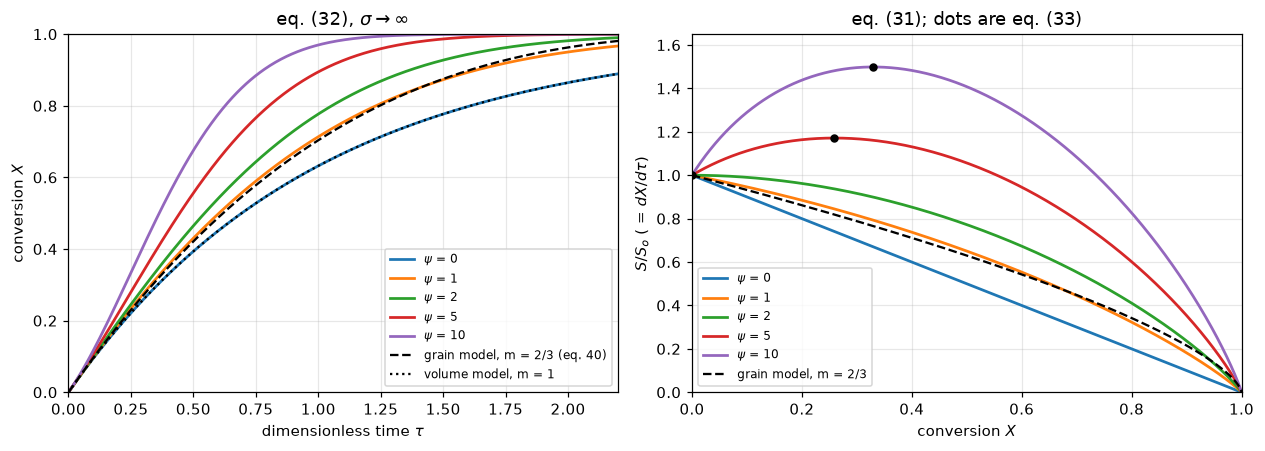

eq. (33) as psi -> infinity: X_M -> 1 - exp(-1/2) = 0.3934693   (printed: X_M < 0.393)
   so the printed bound is a truncation: X_M exceeds 0.393 for psi above 1293.
eq. (33) at the printed threshold psi = 2: X_M = 0.0e+00, so the maximum is born at the particle's start.
Petersen's eq. (34) at eps_o = 0.26: X_M = 0.324324
Petersen's eq. (34) at eps_o = 0.3: X_M = 0.285714


In [6]:
PSI_SHOW = [0.0, 1.0, 2.0, 5.0, 10.0]   # the labels printed on Figure 4's curves
tg = np.linspace(0, 2.2, 601)
fig, ax = plt.subplots(1, 2, figsize=(11.6, 4.2))
for pv in PSI_SHOW:
    ax[0].plot(tg, X_of_tau(tg, pv), lw=1.8, label=fr"$\psi$ = {pv:g}")
tg40 = np.linspace(0, 3, 301)
ax[0].plot(tg40, X_grain(tg40, 2 / 3), "k--", lw=1.5, label="grain model, m = 2/3 (eq. 40)")
ax[0].plot(tg, X_grain(tg, 1.0), "k:", lw=1.5, label="volume model, m = 1")
ax[0].set(xlabel=r"dimensionless time $\tau$", ylabel="conversion $X$", xlim=(0, 2.2), ylim=(0, 1),
          title=r"eq. (32), $\sigma\to\infty$")
ax[0].legend(fontsize=8, loc="lower right")
Xg = np.linspace(1e-6, 1 - 1e-9, 1200)
for pv in PSI_SHOW:
    ax[1].plot(Xg, SS0_of_X(Xg, pv), lw=1.8, label=fr"$\psi$ = {pv:g}")
    if pv >= 2:
        ax[1].plot([XM_eq33(pv)], [SS0_of_X(XM_eq33(pv), pv)], "o", ms=4.5, color="k", zorder=5)
ax[1].plot(Xg, (1 - Xg)**(2 / 3), "k--", lw=1.5, label="grain model, m = 2/3")
ax[1].set(xlabel="conversion $X$", ylabel=r"$S/S_o$ ( = $dX/d\tau$)", xlim=(0, 1), ylim=(0, 1.65),
          title="eq. (31); dots are eq. (33)")
ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()


def xm_sup(denom=2.0):
    """Supremum of eq. (33) as psi -> infinity."""
    return 1 - np.exp(-1 / denom)


def psi_xm_reaches(level, denom=2.0):
    """psi at which eq. (33) reaches ``level``."""
    return unique_root(lambda pv: XM_eq33(pv, denom) - level, 2.0, 1e7, n_scan=64, log=True, xtol=1e-9)


claims.value("XM_sup_vs_printed_rel", abs(xm_sup() - P["XM_sup"]) / P["XM_sup"], rtol=1e-3)
claims.value("XM_exceeds_printed_psi", psi_xm_reaches(P["XM_sup"]), rtol=1e-4)
for lab, d in (("eq. (33) as (2-psi)/psi (XM_eq33(..., denom=1))", 1.0),):
    brk(lab, "XM_sup_vs_printed_rel", abs(xm_sup(d) - P["XM_sup"]) / P["XM_sup"])
    brk(lab, "XM_exceeds_printed_psi", psi_xm_reaches(P["XM_sup"], d))
print(f"eq. (33) as psi -> infinity: X_M -> 1 - exp(-1/2) = {xm_sup():.7f}   (printed: X_M < {P['XM_sup']})")
print(f"   so the printed bound is a truncation: X_M exceeds {P['XM_sup']} for psi above "
      f"{claims['XM_exceeds_printed_psi']:.0f}.")
print(f"eq. (33) at the printed threshold psi = {P['XM_psi_min']:.0f}: X_M = {XM_eq33(P['XM_psi_min']):.1e}, "
      "so the maximum is born at the particle's start.")
for e_ in (P["fig4_eps_o"], P["fig7_eps_o"]):
    print(f"Petersen's eq. (34) at eps_o = {e_}: X_M = {(1 - 2 * e_) / (2 * (1 - e_)):.6f}")

### The Petersen reduction, and a parameter set that is not merely over-determined

The paper claims the Fig. 4 set "satisf[ies] Equations (3) and (4)" and
"give[s] $\psi = 5$", and that curve C's set is "no longer consistent with
the requirements of Petersen's model", whose "corresponding Petersen choices
are not, in this case, uniquely defined". Both are checkable arithmetic, and
the second is stronger than the paper says: eq. (3) has a **maximum** over
$r_p$ at $r_p\sqrt{\pi L/3} = 1/2$ (the stationary point of the symbolic
section), so for a given $L$ no Petersen structure has a surface above
$S_{\max}(L)$.

**Which root of eq. (7)?** The paper says "$G$ is the solution to the cubic
equation", singular. It has three real roots. The symbolic section showed
eq. (7) is exactly $G = 3/(2u_o)$ with $\epsilon_o = 3u_o^2-2u_o^3$, which
selects one of them.

In [7]:
SETS = {"Fig. 4 / p. 384 Petersen set": petersen_audit(P["fig4_So"], P["fig4_Lo"], P["fig4_eps_o"]),
        "Fig. 7 curves A, B": petersen_audit(P["fig7_AB_So"], P["fig7_AB_Lo"], P["fig7_eps_o"]),
        "Fig. 7 curve C": petersen_audit(P["fig7_C_So"], P["fig7_C_Lo"], P["fig7_eps_o"])}
aud = pd.DataFrame(SETS).T[["So", "eps", "Smax", "feasible", "eps_pred", "eps_rel", "S_pred", "S_rel", "psi"]]
with pd.option_context("display.float_format", lambda x: f"{x:.6g}"):
    display(aud)
F4, AB, CC = SETS.values()

claims.value("psi_fig4_vs_printed_rel", abs(F4["psi"] - P["fig4_psi"]) / P["fig4_psi"], rtol=1e-3)
claims.value("petersen_eps_rel_fig4set", F4["eps_rel"], rtol=1e-3)
claims.value("petersen_S_rel_fig4set", F4["S_rel"], rtol=1e-3)
claims.value("petersen_eps_rel_fig7AB", AB["eps_rel"], rtol=1e-3)
claims.value("curveC_So_over_Smax", CC["So"] / CC["Smax"], rtol=1e-4)
L_D, rp_D = curve_D_length(P["fig7_C_So"], P["fig7_eps_o"])
claims.value("curveD_L_over_LAB", L_D / P["fig7_AB_Lo"], rtol=1e-4)


def roundtrip(L):
    """Largest relative miss of eqs. (3) and (4) at curve D's (r_p, L)."""
    return max(abs(pet_S(rp_D, L) - P["fig7_C_So"]) / P["fig7_C_So"],
               abs(pet_eps(rp_D, L) - P["fig7_eps_o"]) / P["fig7_eps_o"])


claims.bound("curveD_roundtrip_rel", roundtrip(L_D), max=1e-14, basis="identity",
             note="eqs. (3) and (4) evaluated at the (r_p, L) solved from them; round-off only")
for kw, lab in ((dict(keep_porosity=False), "psi with (1 - eps_o) dropped (psi_of(..., keep_porosity=False))"),
                (dict(coef=2 * np.pi), "psi with 2 pi for 4 pi (psi_of(..., coef=2*pi))")):
    brk(lab, "psi_fig4_vs_printed_rel",
        abs(psi_of(P["fig4_So"], P["fig4_Lo"], P["fig4_eps_o"], **kw) - P["fig4_psi"]) / P["fig4_psi"])
brk("eq. (3): the root above the surface maximum (petersen_audit(..., root='upper'))", "petersen_eps_rel_fig4set",
    petersen_audit(P["fig4_So"], P["fig4_Lo"], P["fig4_eps_o"], root="upper")["eps_rel"])
brk("eq. (3): the root above the surface maximum (petersen_audit(..., root='upper'))", "petersen_eps_rel_fig7AB",
    petersen_audit(P["fig7_AB_So"], P["fig7_AB_Lo"], P["fig7_eps_o"], root="upper")["eps_rel"])
_bad4 = petersen_audit(P["fig4_So"], P["fig4_Lo"], P["fig4_eps_o"], c=1 / 3)
brk("eq. (4) read as (1 - (r/3) sqrt(pi L/3)) (petersen_audit(..., c=1/3))", "petersen_eps_rel_fig4set", _bad4["eps_rel"])
brk("eq. (4) read as (1 - (r/3) sqrt(pi L/3)) (petersen_audit(..., c=1/3))", "petersen_S_rel_fig4set", _bad4["S_rel"])
brk("curve C's L_o read as 3.14e7 (one decade out)", "curveC_So_over_Smax",
    P["fig7_C_So"] / petersen_audit(P["fig7_C_So"], 10 * P["fig7_C_Lo"], P["fig7_eps_o"])["Smax"])
brk("curve D's S_o read as curves A and B's", "curveD_L_over_LAB",
    curve_D_length(P["fig7_AB_So"], P["fig7_eps_o"])[0] / P["fig7_AB_Lo"])
brk("curve D's length perturbed 1 %", "curveD_roundtrip_rel", roundtrip(1.01 * L_D))

display(Markdown(rf"""
**Both claims about the Fig. 4 set hold.** Eq. (3) then eq. (4) returns
$\epsilon$ = {F4['eps_pred']:.6f} against the printed {P['fig4_eps_o']}
({100*F4['eps_rel']:.2f} %); eq. (4) then eq. (3) returns $S_o$ = {F4['S_pred']:.1f}
against {P['fig4_So']:.0f} ({100*F4['S_rel']:.2f} %); and $\psi$ = {F4['psi']:.4f} against
the printed 5 ({100*claims['psi_fig4_vs_printed_rel']:.2f} %). Curves A and B's triple closes to
{100*AB['eps_rel']:.2f} % in porosity.

**Curve C is infeasible, not merely over-determined.** The largest surface any
Petersen structure of length {P['fig7_C_Lo']:.3g} cm/cm³ can have is
{CC['Smax']:.1f} cm²/cm³, and curve C asks for {P['fig7_C_So']:.0f}, a factor
{claims['curveC_So_over_Smax']:.3f} beyond it: eq. (3) has no root for that pair,
which is why a parameter had to be freed. The same arithmetic reconstructs the
length of curve D, which the paper says "is internally calculated via Equations
(3) and (4)" and never prints: fixing $\epsilon_o$ = {P['fig7_eps_o']} and
$S_o$ = {P['fig7_C_So']:.0f} gives $L$ = {L_D:.4e} cm/cm³, {claims['curveD_L_over_LAB']:.3f}
times curves A and B's (searched: the Fig. 7 caption, both columns of p. 384, and
the p. 383-385 running text; the only lengths printed are $10^7$ on p. 381 and
the shared $3.14\times10^6$).
"""))

for e_ in (P["fig4_eps_o"], P["fig7_eps_o"]):
    rts = cubic7_roots(e_)
    Gsel = G_of_eps(e_)
    print(f"eq. (7) at eps_o = {e_}: real roots {np.array2string(rts, precision=6)}; "
          f"eqs. (3),(4),(6) select G = 3/(2 u_o) = {Gsel:.6f}")
    for g in rts[(rts > 1) & (abs(rts - Gsel) > 1e-6)]:
        print(f"   the other root G = {g:.6f} puts complete gasification at s = 2G/3 - 1 = {2*g/3-1:+.6f} < 0")

,So,eps,Smax,feasible,eps_pred,eps_rel,S_pred,S_rel,psi
Fig. 4 / p. 384 Petersen set,2425,0.26,2720.01,True,0.261931,0.00742862,2419.8,0.00214569,4.96533
"Fig. 7 curves A, B",2500,0.3,2720.01,True,0.292448,0.0251726,2516.57,0.00662752,4.41934
Fig. 7 curve C,12500,0.3,2720.01,False,NaN,NaN,2516.57,0.798674,0.176774



**Both claims about the Fig. 4 set hold.** Eq. (3) then eq. (4) returns
$\epsilon$ = 0.261931 against the printed 0.26
(0.74 %); eq. (4) then eq. (3) returns $S_o$ = 2419.8
against 2425 (0.21 %); and $\psi$ = 4.9653 against
the printed 5 (0.69 %). Curves A and B's triple closes to
2.52 % in porosity.

**Curve C is infeasible, not merely over-determined.** The largest surface any
Petersen structure of length 3.14e+06 cm/cm³ can have is
2720.0 cm²/cm³, and curve C asks for 12500, a factor
4.596 beyond it: eq. (3) has no root for that pair,
which is why a parameter had to be freed. The same arithmetic reconstructs the
length of curve D, which the paper says "is internally calculated via Equations
(3) and (4)" and never prints: fixing $\epsilon_o$ = 0.3 and
$S_o$ = 12500 gives $L$ = 7.7470e+07 cm/cm³, 24.672
times curves A and B's (searched: the Fig. 7 caption, both columns of p. 384, and
the p. 383-385 running text; the only lengths printed are $10^7$ on p. 381 and
the shared $3.14\times10^6$).


eq. (7) at eps_o = 0.26: real roots [-5.536321  1.043805  4.492516]; eqs. (3),(4),(6) select G = 3/(2 u_o) = 4.492516
   the other root G = 1.043805 puts complete gasification at s = 2G/3 - 1 = -0.304130 < 0
eq. (7) at eps_o = 0.3: real roots [-5.181003  1.0517    4.129302]; eqs. (3),(4),(6) select G = 3/(2 u_o) = 4.129302
   the other root G = 1.051700 puts complete gasification at s = 2G/3 - 1 = -0.298866 < 0


### The 75 % claim, to three digits

"Curves A and B are in good agreement up to about 75 % conversion and
diverge thereafter" (p. 384), and in the CONCLUSIONS, "some deviation ... is
found at high conversions (above about 75 %)". Both models are closed forms of
printed parameters, so the claim is a number.

**Which Petersen structure is curve B?** A Petersen solid has two degrees of
freedom $(r_p, L)$, and the caption prints three numbers, so a convention has
to be chosen. The paper prints it, on p. 384:

> The corresponding Petersen choices are not, in this case, uniquely defined.
> If $\epsilon_o = 0.3$ and $L_o = 3.14 \times 10^6$ are chosen, the results
> are the same as the prior curve B. If, on the other hand, $\epsilon_o = 0.3$
> and $S_o = 12{,}500$ cm²/cm³ are fixed, curve D is obtained.

So curve B is the Petersen structure fixed by $(\epsilon_o, L_o)$. An
over-determined triple has three pairings, so the other two, $(\epsilon_o,
S_o)$ and $(S_o, L_o)$, are computed beside it. Every location below is a
root: the crossings of $X_A - X_B$, its extrema (roots of its analytic
derivative), and the parting conversion (the first root of
$|X_A - X_B| - 0.02$), each by `find_roots` on a logarithmic scan of time.

crossings and extrema found on 100, 400 and 1600 scan points: (2, 3), (2, 3), (2, 3)


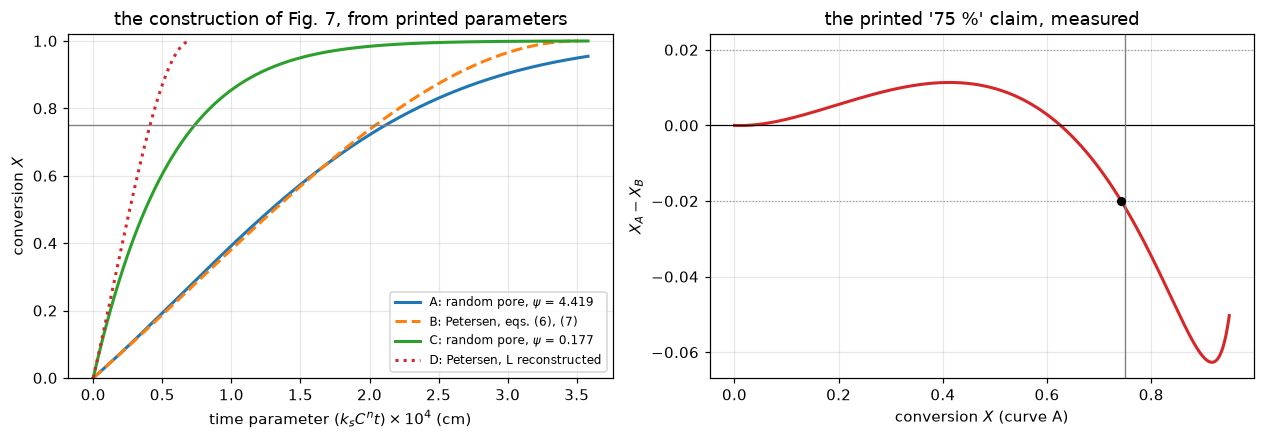


Curve A has $\psi$ = 4.4193, so it has a rate maximum (at $X_M$ = 0.2395).
**Up to $X$ = 0.75 the two curves differ by at most
0.0218 in conversion** (at $X$ = 0.75 itself, where the
gap is still growing), and **they first part by 0.02 at $X$ = 0.7423**: the
printed "about 75 %", to three digits. The two curves cross twice. Petersen's
initial rate is 0.66 % the faster, so curve A trails
curve B up to $X$ = 0.0232 (by at most 3.7e-05 in $X$) before
overtaking; the second crossing is at $X$ = 0.6257. Curve A leads by at most
0.0114 before it and trails by at most 0.0627 after it, at
$X$ = 0.9164.

**The third digit is the paper's convention.** Fixing curve B by $(\epsilon_o, S_o)$
instead (the pairing p. 384 assigns to curve D; it implies $L$ =
3.0988e+06 cm/cm³) gives a largest gap of
0.0177 and a parting conversion of
0.7599; fixing it by $(S_o, L_o)$, which keeps both printed
measurements and takes the porosity 0.2924 of the previous section,
gives 0.0165 and 0.7687. The parting
conversion therefore moves in the second digit across the three readings; all
round to "about 75 %", and only the paper's own convention earns the three-digit
statement.

**The surfaces part far earlier than the conversions.** On the Fig. 4 set the
random pore surface is +4.54 % against Petersen's at
$X$ = 0.25 and -21.66 % at $X$ = 0.75; on curves A and B's set
+4.70 % and -21.00 %.


In [8]:
FIG7 = {pr: Fig7(P["fig7_AB_So"], P["fig7_AB_Lo"], P["fig7_eps_o"], pairing=pr) for pr in ("eps_L", "eps_S", "S_L")}
CMP = {pr: f.compare(X_upto=P["fig7_agreement_X"]) for pr, f in FIG7.items()}
FA, CA = FIG7["eps_L"], CMP["eps_L"]
_scan_counts = {n: (len(FA.compare(n_scan=n)["crossings"]), len(FA.compare(n_scan=n)["extrema"])) for n in (100, 1600)}
print(f"crossings and extrema found on 100, 400 and 1600 scan points: {_scan_counts[100]}, "
      f"{(len(CA['crossings']), len(CA['extrema']))}, {_scan_counts[1600]}")
assert _scan_counts[100] == _scan_counts[1600] == (len(CA["crossings"]), len(CA["extrema"]))
X_cross = [float(FA.XA(k)) for k in CA["crossings"]]
X_ext = [float(FA.XA(k)) for k in CA["extrema"]]
d_ext = [float(FA.dAB(k)) for k in CA["extrema"]]
RATE0_A = P["fig7_AB_So"] / (1 - P["fig7_eps_o"])                        # dX_A/d(k_s C^n t) at t = 0
RATE0_B = RATE0_A - float(FA.ddAB(0.0))                                 # d(eq. 6)/ds over r_po at s = 0


def fig7_claims(f, c):
    """The numbers of the comparison, for one Fig7 and its compare()."""
    xc = [float(f.XA(k)) for k in c["crossings"]] + [np.nan, np.nan]
    de = [float(f.dAB(k)) for k in c["extrema"] if f.XA(k) > 0.05] + [np.nan, np.nan]
    return dict(max_upto=c["max_upto"], X_part=c["X_part"], early=xc[0], second=xc[1],
                lead=de[0], trail=-de[1])


V = fig7_claims(FA, CA)
assert V["max_upto"] == abs(FA.dAB(CA["kt_upto"])), "the largest gap up to X = 0.75 is at X = 0.75 itself"
claims.value("fig7_max_dX_upto_75", V["max_upto"], rtol=1e-3)
claims.value("fig7_X_at_two_points", V["X_part"], rtol=1e-4)
claims.value("fig7_early_cross_X", V["early"], rtol=1e-3)
claims.value("fig7_second_cross_X", V["second"], rtol=1e-3)
claims.value("fig7_lead_max", V["lead"], rtol=1e-3)
claims.value("fig7_trail_max", V["trail"], rtol=1e-3)
claims.value("fig7_rate0_excess", RATE0_B / RATE0_A - 1, rtol=1e-3)
for pr, tag in (("eps_S", "eps_S"), ("S_L", "S_L")):
    claims.value(f"fig7_X_part_{tag}", CMP[pr]["X_part"], rtol=1e-4)
    claims.value(f"fig7_max_dX_{tag}", CMP[pr]["max_upto"], rtol=1e-3)

G_WRONG = float(cubic7_roots(P["fig7_eps_o"])[1])
for lab, kw in ((f"the middle root of eq. (7), G = {G_WRONG:.4f} (Fig7(..., G=...))", dict(G=G_WRONG)),
                ("eq. (32) with psi tau/2 for psi tau/4 (Fig7(..., quarter=2))", dict(quarter=2.0))):
    fb = Fig7(P["fig7_AB_So"], P["fig7_AB_Lo"], P["fig7_eps_o"], **kw)
    cb = fb.compare(X_upto=P["fig7_agreement_X"])
    Vb = fig7_claims(fb, cb)
    for k, name in (("max_upto", "fig7_max_dX_upto_75"), ("X_part", "fig7_X_at_two_points"),
                    ("early", "fig7_early_cross_X"), ("second", "fig7_second_cross_X"),
                    ("lead", "fig7_lead_max"), ("trail", "fig7_trail_max")):
        brk(lab, name, Vb[k])
    if "G" in kw:
        brk(lab, "fig7_rate0_excess", (RATE0_A - fb.ddAB(0.0)) / RATE0_A - 1)
    for pr, tag in (("eps_S", "eps_S"), ("S_L", "S_L")):
        if "quarter" in kw:
            cq = Fig7(P["fig7_AB_So"], P["fig7_AB_Lo"], P["fig7_eps_o"], pairing=pr, **kw).compare(
                X_upto=P["fig7_agreement_X"])
            brk(lab, f"fig7_X_part_{tag}", cq["X_part"])
            brk(lab, f"fig7_max_dX_{tag}", cq["max_upto"])

# the surfaces, on both printed parameter sets
def surf_dev(X, So_, Lo_, e_, **kw):
    """Relative gap of the random pore surface to Petersen's at conversion X."""
    return float(SS0_of_X(X, psi_of(So_, Lo_, e_, **kw)) / SS0_petersen(np.array([X]), e_)[0] - 1)


SURF = {}
for tag, (So_, Lo_, e_) in (("f4", (P["fig4_So"], P["fig4_Lo"], P["fig4_eps_o"])),
                            ("AB", (P["fig7_AB_So"], P["fig7_AB_Lo"], P["fig7_eps_o"]))):
    for Xv, xt in ((0.25, "25"), (0.75, "75")):
        name = f"surf_dev_{tag}_{xt}"
        SURF[name] = surf_dev(Xv, So_, Lo_, e_)
        claims.value(name, SURF[name], rtol=1e-3)
        brk("psi with (1 - eps_o) dropped (psi_of(..., keep_porosity=False))", name,
            surf_dev(Xv, So_, Lo_, e_, keep_porosity=False))

ktp = np.linspace(1e-9, FA.kt_end * 1.02, 900)
fig, ax = plt.subplots(1, 2, figsize=(11.6, 4.1))
ax[0].plot(ktp * 1e4, FA.XA(ktp), lw=2, label=f"A: random pore, $\\psi$ = {FA.psi:.3f}")
kB = ktp[ktp <= FA.kt_end]
ax[0].plot(kB * 1e4, FA.XB(kB), "--", lw=2, label="B: Petersen, eqs. (6), (7)")
psi_C = psi_of(P["fig7_C_So"], P["fig7_C_Lo"], P["fig7_eps_o"])
ax[0].plot(ktp * 1e4, X_of_tau(ktp * P["fig7_C_So"] / (1 - P["fig7_eps_o"]), psi_C), lw=2,
           label=f"C: random pore, $\\psi$ = {psi_C:.3f}")
rpoD = u_of_eps(P["fig7_eps_o"]) / np.sqrt(np.pi * L_D / 3)
kD = ktp[ktp <= rpoD * (2 * G_of_eps(P["fig7_eps_o"]) / 3 - 1)]
ax[0].plot(kD * 1e4, X_petersen(kD / rpoD, P["fig7_eps_o"]), ":", lw=2, label="D: Petersen, L reconstructed")
ax[0].axhline(P["fig7_agreement_X"], color="0.5", lw=0.9)
ax[0].set(xlabel=r"time parameter $(k_s C^n t)\times 10^{4}$ (cm)", ylabel="conversion $X$", ylim=(0, 1.02),
          title="the construction of Fig. 7, from printed parameters")
ax[0].legend(fontsize=8, loc="lower right")
ax[1].plot(FA.XA(kB), FA.dAB(kB), lw=2, color="C3")
for y in (0.0, 0.02, -0.02):
    ax[1].axhline(y, color="k" if y == 0 else "0.6", lw=0.8, ls="-" if y == 0 else ":")
ax[1].axvline(P["fig7_agreement_X"], color="0.5", lw=0.9)
ax[1].plot([V["X_part"]], [FA.dAB(FA.kt_at_XA(V["X_part"]))], "ko", ms=5)
ax[1].set(xlabel="conversion $X$ (curve A)", ylabel="$X_A - X_B$", title="the printed '75 %' claim, measured")
fig.tight_layout(); plt.show()

display(Markdown(rf"""
Curve A has $\psi$ = {FA.psi:.4f}, so it has a rate maximum (at $X_M$ = {XM_eq33(FA.psi):.4f}).
**Up to $X$ = {P['fig7_agreement_X']} the two curves differ by at most
{claims['fig7_max_dX_upto_75']:.4f} in conversion** (at $X$ = 0.75 itself, where the
gap is still growing), and **they first part by 0.02 at $X$ = {V['X_part']:.4f}**: the
printed "about 75 %", to three digits. The two curves cross twice. Petersen's
initial rate is {100*claims['fig7_rate0_excess']:.2f} % the faster, so curve A trails
curve B up to $X$ = {V['early']:.4f} (by at most {abs(d_ext[0]):.1e} in $X$) before
overtaking; the second crossing is at $X$ = {V['second']:.4f}. Curve A leads by at most
{V['lead']:.4f} before it and trails by at most {V['trail']:.4f} after it, at
$X$ = {X_ext[2]:.4f}.

**The third digit is the paper's convention.** Fixing curve B by $(\epsilon_o, S_o)$
instead (the pairing p. 384 assigns to curve D; it implies $L$ =
{FIG7['eps_S'].L_B:.4e} cm/cm³) gives a largest gap of
{claims['fig7_max_dX_eps_S']:.4f} and a parting conversion of
{claims['fig7_X_part_eps_S']:.4f}; fixing it by $(S_o, L_o)$, which keeps both printed
measurements and takes the porosity {FIG7['S_L'].eps_B:.4f} of the previous section,
gives {claims['fig7_max_dX_S_L']:.4f} and {claims['fig7_X_part_S_L']:.4f}. The parting
conversion therefore moves in the second digit across the three readings; all
round to "about 75 %", and only the paper's own convention earns the three-digit
statement.

**The surfaces part far earlier than the conversions.** On the Fig. 4 set the
random pore surface is {100*SURF['surf_dev_f4_25']:+.2f} % against Petersen's at
$X$ = 0.25 and {100*SURF['surf_dev_f4_75']:+.2f} % at $X$ = 0.75; on curves A and B's set
{100*SURF['surf_dev_AB_25']:+.2f} % and {100*SURF['surf_dev_AB_75']:+.2f} %.
"""))

### Why they part: two different overlap laws

The abstract says the models "approach" each other at zero pore-size
variance, not that they coincide, and the paper's explanation is "the neglect
of new intersections of reaction surfaces in the Petersen approach". Both
models write the porosity as a function of the non-overlapped volume $V_E$:
Avrami's eq. (20) gives $V = 1-e^{-V_E}$, while Petersen's eqs. (3)-(4) in
$u = r\sqrt{\pi L/3}$ give $V_E = 3u^2$ and $V = 3u^2-2u^3$. Expanded,

$$V_{\text{Avrami}} = V_E - \tfrac12 V_E^2 + \ldots, \qquad
V_{\text{Petersen}} = V_E - 2\left(\tfrac{V_E}{3}\right)^{3/2},$$

so they differ already at order $V_E^{3/2}$, and no parameter choice makes the
two models identical. Petersen's law reaches $V = 1$ at finite $u = 1$ while
Avrami's only approaches it, which is where the high-conversion divergence
comes from. The crossing is a root of the gap, the largest gap a root of its
derivative, $6u\,(e^{-3u^2} - 1 + u)$.

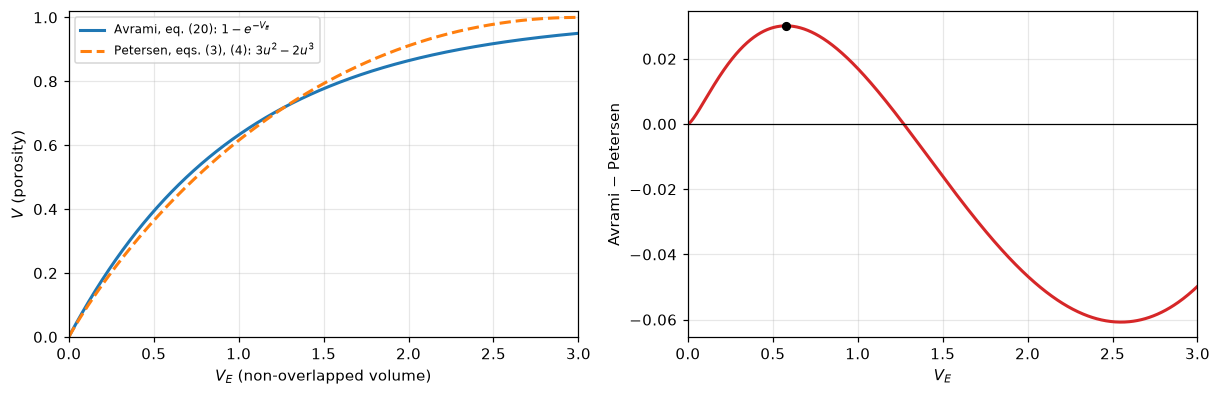

the two overlap laws cross once, at u = 0.6508058 (V_E = 1.270645); largest gap 0.030118 in porosity, at u = 0.438849.
at V_E = 0.01 the leading term 2(V_E/3)^(3/2) - V_E^2/2 accounts for the gap to 5.0e-04 relative.


In [9]:
def overlap_numbers(c=2.0):
    """Crossing (u), largest gap and the leading-term check at V_E = 0.01."""
    cross = unique_root(lambda z: overlap_gap(z, c), 1e-6, 1.0, n_scan=64)
    top = [z for z in find_roots(lambda z: overlap_gap_slope(z, c), 1e-6, cross, n_scan=64, xtol=1e-15)["roots"]]
    VE = 0.01
    lead = abs(((1 - np.exp(-VE)) - (VE - c * (VE / 3)**1.5)) / (2 * (VE / 3)**1.5 - VE**2 / 2) - 1)
    return cross, float(overlap_gap(top[0], c)), top[0], lead


U_CROSS, GAP_MAX, U_GAP, LEAD_REL = overlap_numbers()
claims.value("overlap_cross_u", U_CROSS, rtol=1e-6)
claims.value("overlap_max_gap", GAP_MAX, rtol=1e-6)
claims.bound("overlap_lead_rel", LEAD_REL, max=1e-3, basis="theory",
             note="the leading term 2(V_E/3)^(3/2) - V_E^2/2 against the gap at V_E = 0.01; the next term is O(V_E)")
_c1 = overlap_numbers(c=1.0)
for name, val in zip(("overlap_cross_u", "overlap_max_gap", None, "overlap_lead_rel"), _c1):
    if name:
        brk("eq. (4) read as (1 - (r/3) sqrt(pi L/3)) (overlap_gap(..., c=1))", name, val)

ug = np.linspace(0, 1, 1201)
fig, ax = plt.subplots(1, 2, figsize=(11.2, 3.7))
ax[0].plot(3 * ug**2, 1 - np.exp(-3 * ug**2), lw=2, label="Avrami, eq. (20): $1-e^{-V_E}$")
ax[0].plot(3 * ug**2, 3 * ug**2 - 2 * ug**3, "--", lw=2, label="Petersen, eqs. (3), (4): $3u^2-2u^3$")
ax[0].set(xlabel="$V_E$ (non-overlapped volume)", ylabel="$V$ (porosity)", xlim=(0, 3), ylim=(0, 1.02))
ax[0].legend(fontsize=8)
ax[1].plot(3 * ug**2, overlap_gap(ug), lw=2, color="C3"); ax[1].axhline(0, color="k", lw=0.8)
ax[1].plot([3 * U_GAP**2], [GAP_MAX], "ko", ms=5)
ax[1].set(xlabel="$V_E$", ylabel="Avrami $-$ Petersen", xlim=(0, 3))
fig.tight_layout(); plt.show()
print(f"the two overlap laws cross once, at u = {U_CROSS:.7f} (V_E = {3*U_CROSS**2:.6f}); "
      f"largest gap {GAP_MAX:.6f} in porosity, at u = {U_GAP:.6f}.")
print(f"at V_E = 0.01 the leading term 2(V_E/3)^(3/2) - V_E^2/2 accounts for the gap to {LEAD_REL:.1e} relative.")

### The grain shape factor: the paper's own least squares, re-run

The paper defines $m$ by minimising $I$ and reports the result as Figure 6
and two sentences. $I$ has a closed form: with $w = 1-X = e^{-v}$ every term
is an incomplete gamma function,

$$J(b) = \int_0^1 w^{b}\sqrt{1-\psi\ln w}\,dw
= \frac{e^{c}}{\psi}\left(\frac{\psi}{b+1}\right)^{3/2}\Gamma(3/2, c),
\qquad c = \frac{b+1}{\psi},$$

so $I = \left(\tfrac13+\tfrac{\psi}{9}\right) - 2J(m{+}1) + \tfrac{1}{2m+1}$.
The best $m$ is the root of $dI/dm$ (its $J$ derivative by 600-point
Gauss-Legendre quadrature), the only one on a scan of
$-0.45 < m < 3$; the second route is the root of the same derivative at 40
digits (`mpmath`). A bounded minimiser of the closed-form $I$ is printed as an
illustration of what its cancellation noise does to the location of the minimum.
Reported alongside is a normalised misfit, $\sqrt{I/(\tfrac13+\tfrac{\psi}{9})}$,
the denominator being the same integral with the grain term removed. It is what
makes "grossly inadequate" a number.

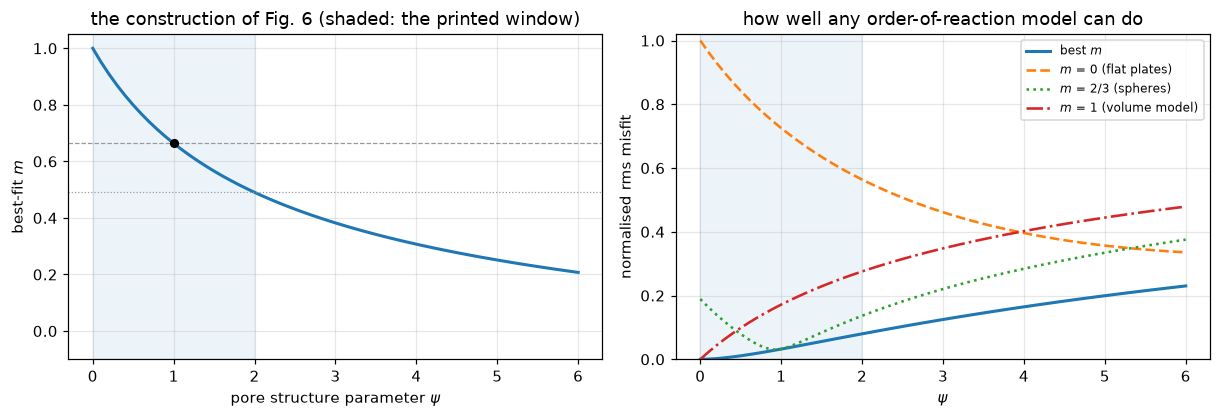


**Printed: "For $0 \le \psi \le 2$, the best fit gives $0.49 \le m \le 1$."**
Computed over the same window (monotone, 41 points checked): $m^\star(0)$ =
1.0000000000, the volume model, and $m^\star(2)$ = 0.4905224. **Printed: "For $\psi = 1$, the
best $m$ is very close to two-thirds."** Computed: $m^\star(1)$ = 0.6638850,
0.417 % below 2/3. The two routes to
$m^\star$ (the root of $dI/dm$ by quadrature and at 40 digits) agree to below 1e-11 (here
3.2e-13). A bounded minimiser of the closed-form $I$ is
not a second route of that quality: it differs from the root by
1.2e-07 at worst over the same $\psi$, because $I$ carries about
1e-15 of cancellation noise at its minimum and the minimiser resolves $m$ only to
about the square root of that.

**How good is the best $m$?** Its normalised misfit is
7.99 % at $\psi$ = 2, reaching 8 % at $\psi$ = 2.0013, and rises with $\psi$, to 19.9 % at
$\psi$ = 5 and 32.3 % at $\psi$ = 10, because no order-of-reaction model
can produce a rate maximum. The abstract's "not consistent with the assumption of
flat plate grains ($m = 0$) for any pore structure" holds as a claim about fit
quality: at $\psi$ = 2, $m$ = 0 misfits by 56.4 %. The
unconstrained optimum does pass through $m$ = 0, at exactly one value,
$\psi$ = 16.8046, outside the printed window, and there its misfit is
42.1 %. The paper never evaluates $m^\star$
outside $0 \le \psi \le 2$ (searched: abstract, CONCLUSIONS, the Figure 6
discussion and caption), so this statement is the page's, not the paper's.


every printed m (eq. 39's closed form has a branch at m = 1):
   m = 0.000000 (flat plates ) X(tau = 0.4) = 0.4000000000   misfit at psi = 1: 72.5231 %
   m = 0.500000 (cylinders   ) X(tau = 0.4) = 0.3600000000   misfit at psi = 1: 11.6012 %
   m = 0.666667 (spheres     ) X(tau = 0.4) = 0.3490370370   misfit at psi = 1: 3.2214 %
   m = 1.000000 (volume model) X(tau = 0.4) = 0.3296799540   misfit at psi = 1: 17.1660 %
   the m -> 1 branch is continuous: |X(m = 1) - X(m = 1 - 1e-9)| below 1e-7 (here 3.0e-08)


In [10]:
M0, M1, M2 = m_star(0.0), m_star(1.0), m_star(P["m_psi_window_hi"])
claims.value("m_star_psi0", M0, rtol=1e-9)
claims.value("m_star_psi1", M1, rtol=1e-6)
claims.value("m_star_psi2", M2, rtol=1e-6)
claims.value("m_star_psi1_vs_two_thirds_rel", abs(M1 - P["grain_m_sphere"]) / P["grain_m_sphere"], rtol=1e-3)
PSI_TWO = (0.5, 1.0, 1.5, 2.0)
mpmath.mp.dps = 40


def m_star_mp(pv):
    """Root of dI/dm at 40 digits: dI/dm = 2 int_0^inf v exp(-(m+2) v) sqrt(1 + psi v) dv - 2/(2m+1)^2."""
    p_ = mpmath.mpf(pv)

    def d(z):
        return 2 * mpmath.quad(lambda v: v * mpmath.exp(-(z + 2) * v) * mpmath.sqrt(1 + p_ * v),
                               [0, 1, 10, mpmath.inf]) - 2 / (2 * z + 1)**2
    return float(mpmath.findroot(d, mpmath.mpf(m_star(pv))))


claims.bound("m_star_two_routes", max(abs(m_star(pv) - m_star_mp(pv)) for pv in PSI_TWO), max=1e-11,
             basis="tolerance", note="the 600-point quadrature of dI/dm at round-off, 1e-13 in m, against a 40-digit root")
MSTAR_BRENT_GAP = {pv: abs(m_star(pv) - m_star_brent(pv)) for pv in PSI_TWO}
psi_fine = np.linspace(0, P["m_psi_window_hi"], 41)
m_fine = np.array([m_star(float(pv)) for pv in psi_fine])
assert np.all(np.diff(m_fine) < 0), "m*(psi) is monotone on the printed window"
NRMS = {pv: I_nrms(pv, m_star(pv)) for pv in (2.0, 5.0, 10.0)}
claims.value("nrms_best_psi2", NRMS[2.0], rtol=1e-4)


def psi_nrms_reaches(level, p=1):
    """psi at which the best-m misfit reaches ``level``, bracketed on [0.1, 4]."""
    return unique_root(lambda pv: I_nrms(pv, m_star(pv, p=p), p=p) - level, 0.1, 4.0, n_scan=32, xtol=1e-12)


claims.value("nrms_8pct_psi", psi_nrms_reaches(0.08), rtol=1e-5)
claims.value("nrms_best_psi5", NRMS[5.0], rtol=1e-3)
claims.value("nrms_best_psi10", NRMS[10.0], rtol=1e-3)
claims.value("nrms_m0_psi2", I_nrms(2.0, P["grain_m_flatplate"]), rtol=1e-3)
PSI_M0 = psi_m_star_zero()
claims.value("psi_m_star_zero", PSI_M0, rtol=1e-6)
claims.value("nrms_at_psi_m_star_zero", I_nrms(PSI_M0, 0.0), rtol=1e-3)
BRANCH = abs(X_grain(0.4, 1.0) - X_grain(0.4, 1 - 1e-9))
claims.bound("grain_branch_gap_at_m1", BRANCH, max=1e-7, basis="theory",
             note="the general form of eq. (39) at m = 1 - 1e-9 against its m = 1 branch; the gap is O(1 - m)")

lab_p0 = "I with the (1-X)^1 factor dropped (m_star(..., p=0))"
for name, val in (("m_star_psi0", m_star(0.0, p=0)), ("m_star_psi1", m_star(1.0, p=0)),
                  ("m_star_psi2", m_star(2.0, p=0)),
                  ("m_star_psi1_vs_two_thirds_rel", abs(m_star(1.0, p=0) - 2 / 3) / (2 / 3)),
                  ("m_star_two_routes", max(abs(m_star(pv, p=0) - m_star_mp(pv)) for pv in PSI_TWO)),
                  ("nrms_best_psi2", I_nrms(2.0, m_star(2.0, p=0), p=0)),
                  ("nrms_best_psi5", I_nrms(5.0, m_star(5.0, p=0), p=0)),
                  ("nrms_best_psi10", I_nrms(10.0, m_star(10.0, p=0), p=0)),
                  ("nrms_m0_psi2", I_nrms(2.0, 0.0, p=0))):
    brk(lab_p0, name, val)
brk(lab_p0, "nrms_8pct_psi", psi_nrms_reaches(0.08, p=0))
PSI_M0_HALF = psi_m_star_zero(X_max=0.5)
brk("I truncated to X <= 0.5 (psi_m_star_zero(X_max=0.5))", "psi_m_star_zero", PSI_M0_HALF)
brk("I truncated to X <= 0.5 (psi_m_star_zero(X_max=0.5))", "nrms_at_psi_m_star_zero", I_nrms(PSI_M0_HALF, 0.0))
brk("eq. (39)'s general form taken at m = 0.999 for the m = 1 branch", "grain_branch_gap_at_m1",
    abs(X_grain(0.4, 1.0) - X_grain(0.4, 0.999)))

fig, ax = plt.subplots(1, 2, figsize=(11.2, 3.9))
psi_wide = np.linspace(0, 6, 61)
ax[0].plot(psi_wide, [m_star(float(pv)) for pv in psi_wide], lw=2)
ax[0].axvspan(0, P["m_psi_window_hi"], color="C0", alpha=0.08)
ax[0].axhline(P["m_range_lo"], color="0.6", lw=0.8, ls=":")
ax[0].axhline(P["grain_m_sphere"], color="0.6", lw=0.8, ls="--")
ax[0].plot([1.0], [M1], "ko", ms=5)
ax[0].set(xlabel=r"pore structure parameter $\psi$", ylabel="best-fit $m$",
          title="the construction of Fig. 6 (shaded: the printed window)", ylim=(-0.1, 1.05))
ax[1].plot(psi_wide, [I_nrms(pv, m_star(float(pv))) for pv in psi_wide], lw=2, label="best $m$")
for m_, st, lab in ((P["grain_m_flatplate"], "--", "$m$ = 0 (flat plates)"),
                    (P["grain_m_sphere"], ":", "$m$ = 2/3 (spheres)"),
                    (P["grain_m_volume"], "-.", "$m$ = 1 (volume model)")):
    ax[1].plot(psi_wide, [I_nrms(pv, m_) for pv in psi_wide], st, lw=1.7, label=lab)
ax[1].axvspan(0, P["m_psi_window_hi"], color="C0", alpha=0.08)
ax[1].set(xlabel=r"$\psi$", ylabel="normalised rms misfit", ylim=(0, 1.02),
          title="how well any order-of-reaction model can do")
ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

display(Markdown(rf"""
**Printed: "For $0 \le \psi \le 2$, the best fit gives $0.49 \le m \le 1$."**
Computed over the same window (monotone, 41 points checked): $m^\star(0)$ =
{M0:.10f}, the volume model, and $m^\star(2)$ = {M2:.7f}. **Printed: "For $\psi = 1$, the
best $m$ is very close to two-thirds."** Computed: $m^\star(1)$ = {M1:.7f},
{100*claims['m_star_psi1_vs_two_thirds_rel']:.3f} % below 2/3. The two routes to
$m^\star$ (the root of $dI/dm$ by quadrature and at 40 digits) agree to below 1e-11 (here
{claims['m_star_two_routes']:.1e}). A bounded minimiser of the closed-form $I$ is
not a second route of that quality: it differs from the root by
{max(MSTAR_BRENT_GAP.values()):.1e} at worst over the same $\psi$, because $I$ carries about
1e-15 of cancellation noise at its minimum and the minimiser resolves $m$ only to
about the square root of that.

**How good is the best $m$?** Its normalised misfit is
{100*NRMS[2.0]:.2f} % at $\psi$ = 2, reaching 8 % at $\psi$ = {claims['nrms_8pct_psi']:.4f}, and rises with $\psi$, to {100*NRMS[5.0]:.1f} % at
$\psi$ = 5 and {100*NRMS[10.0]:.1f} % at $\psi$ = 10, because no order-of-reaction model
can produce a rate maximum. The abstract's "not consistent with the assumption of
flat plate grains ($m = 0$) for any pore structure" holds as a claim about fit
quality: at $\psi$ = 2, $m$ = 0 misfits by {100*claims['nrms_m0_psi2']:.1f} %. The
unconstrained optimum does pass through $m$ = 0, at exactly one value,
$\psi$ = {PSI_M0:.4f}, outside the printed window, and there its misfit is
{100*claims['nrms_at_psi_m_star_zero']:.1f} %. The paper never evaluates $m^\star$
outside $0 \le \psi \le 2$ (searched: abstract, CONCLUSIONS, the Figure 6
discussion and caption), so this statement is the page's, not the paper's.
"""))
print("every printed m (eq. 39's closed form has a branch at m = 1):")
for m_, lab in ((P["grain_m_flatplate"], "flat plates"), (P["grain_m_cylinder"], "cylinders"),
                (P["grain_m_sphere"], "spheres"), (P["grain_m_volume"], "volume model")):
    print(f"   m = {m_:.6f} ({lab:<12s}) X(tau = 0.4) = {float(X_grain(0.4, m_)):.10f}   misfit at psi = 1: "
          f"{100*I_nrms(1.0, m_):.4f} %")
print(f"   the m -> 1 branch is continuous: |X(m = 1) - X(m = 1 - 1e-9)| below 1e-7 (here {BRANCH:.1e})")

### The printed defects

Three, each proved from the paper's own content and none repaired. Defect 1
(Park and Levenspiel, 1976 in the text against 1975 in the reference list) is
in the data section.

**Defect 2: "This match at $m = 1$" (p. 383).** Verbatim, with the sentence
before it: *"In either figure, it is clear that the grain model predictions
match the $\psi = 1$ results within the limits of the usual experimental
error. This match at $m = 1$ combined with the above-mentioned correspondence
as $\psi \to 0$ suggests that..."* [*sic*]. The dashed line in Figures 3 and
4 is labelled "GRAIN MODEL, $m = 2/3$"; the "correspondence as $\psi \to 0$"
is already the $m = 1$ case; and Figure 6 puts $m \approx 2/3$ at $\psi = 1$.
Whether the slip is "$m = 1$" for "$\psi = 1$" or for "$m = 2/3$" cannot be
decided from the document, so neither repair is asserted.

**Defect 3: the optimal-porosity worked example (p. 383).** *"If, for
example, a final $\epsilon = 0.3$ is sought for a solid where
$(S_o^2/2\pi L_o) = 0.67$, the initial $\epsilon_o$ should be 0.1 to maximize
the final surface area."* The printed 0.1 is not a root of the paper's own
eq. (35). The optimum is flat, so the surface it costs is small, which is
presumably where a one-figure answer came from; it is reported because eq.
(35) is an equation. Two typographical slips are recorded without comment:
"not clearly indentified" [*sic*, p. 382] and "This research was support by"
[*sic*, p. 385]; the NOTATION list spells "stoichimetric" [*sic*] for $p, q$.

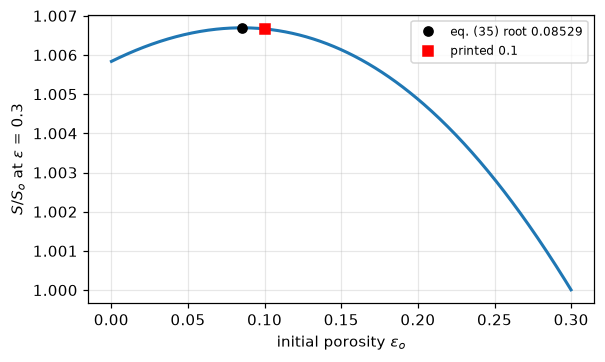


**Defect 2 in numbers.** At $\psi$ = 1 the best $m$ is 0.6639; the printed $m$ = 1
misfits by 17.17 %, a factor
5.34 worse than the optimum. $m$ = 1 is the exact optimum,
but at $\psi$ = 0.

**Defect 3 in numbers.** Eq. (35) at $\epsilon$ = 0.3 and $S_o^2/2\pi L_o$ = 0.67
has its root at $\epsilon_o$ = 0.0852877 by the pymrm block solve, and the direct
maximisation of eq. (27) agrees to below 1e-7 (here 2.5e-08). At the
printed 0.1 the residual is 4.241e-03, and the surface is
2.76e-05 of the maximum below it. Inequality (36)'s
window at $\epsilon$ = 0.3 is [0.6433, 0.7], so the printed
"$\le$ 0.64 violates (36)" is the rounded-down lower bound, consistent. Eq. (35) has a
second root, at $\epsilon_o$ = 0.494674 > $\epsilon$: a minimum of the surface
(0.987744 against 1.006694), and unphysical for a
reaction that opens porosity.


In [11]:
claims.value("nrms_m1_at_psi1", I_nrms(1.0, P["grain_m_volume"]), rtol=1e-4)
claims.value("m1_penalty_at_psi1", I_nrms(1.0, P["grain_m_volume"]) / I_nrms(1.0, M1), rtol=1e-4)
brk(lab_p0, "nrms_m1_at_psi1", I_nrms(1.0, 1.0, p=0))
brk(lab_p0, "m1_penalty_at_psi1", I_nrms(1.0, 1.0, p=0) / I_nrms(1.0, m_star(1.0, p=0), p=0))

EPS_F, GHAT = P["opt_eps_final"], P["opt_group"]


def eq35_numbers(Ghat_root=GHAT, Ghat_direct=GHAT):
    """Root of eq. (35) (pymrm block), the maximiser of eq. (27), the residual and the cost at 0.1."""
    root = float(eps_o_opt_block(EPS_F, Ghat_root)[0])
    direct = minimize_scalar(lambda z: -S_of_eps_o(z, EPS_F, Ghat_direct), bounds=(1e-9, EPS_F - 1e-9),
                             method="bounded", options=dict(xatol=1e-15)).x
    all_roots = find_roots(lambda z: stat35(z, EPS_F, Ghat_root), 1e-9, 0.999, n_scan=64, xtol=1e-16)["roots"]
    return dict(root=root, two_routes=abs(root - direct), all=all_roots,
                resid=abs(stat35(P["opt_eps_o"], EPS_F, Ghat_root)),
                deficit=1 - S_of_eps_o(P["opt_eps_o"], EPS_F, Ghat_root) / S_of_eps_o(root, EPS_F, Ghat_root))


E35 = eq35_numbers()
assert len(E35["all"]) == 2 and abs(E35["all"][0] - E35["root"]) < 1e-12
claims.value("eq35_root_eps_o", E35["root"], rtol=1e-6)
claims.value("eq35_residual_at_printed", E35["resid"], rtol=1e-4)
claims.bound("eq35_two_routes", E35["two_routes"], max=1e-7, basis="tolerance",
             note="bounded maximisation of eq. (27) locates its maximiser to about the square root of eps")
claims.value("eq35_S_deficit_at_printed", E35["deficit"], rtol=1e-3)
claims.value("eq35_second_root", E35["all"][1], rtol=1e-6)
for G_bad in (0.68, 0.66):
    Eb = eq35_numbers(G_bad, G_bad)
    lab = f"the printed group 0.67 read as {G_bad} (eps_o_opt_block(..., {G_bad}))"
    brk(lab, "eq35_root_eps_o", Eb["root"])
    if G_bad == 0.68:
        brk(lab, "eq35_residual_at_printed", Eb["resid"])
        brk(lab, "eq35_second_root", Eb["all"][1])
        brk(lab + " in the root route only", "eq35_two_routes", eq35_numbers(G_bad, GHAT)["two_routes"])
        brk(lab + " in the root only", "eq35_S_deficit_at_printed",
            1 - S_of_eps_o(P["opt_eps_o"], EPS_F, GHAT) / S_of_eps_o(Eb["root"], EPS_F, GHAT))

e0g = np.linspace(1e-4, EPS_F - 1e-4, 400)
fig, ax = plt.subplots(figsize=(5.6, 3.4))
ax.plot(e0g, S_of_eps_o(e0g, EPS_F, GHAT), lw=2)
ax.plot([E35["root"]], [S_of_eps_o(E35["root"], EPS_F, GHAT)], "ko", ms=6, label=f"eq. (35) root {E35['root']:.5f}")
ax.plot([P["opt_eps_o"]], [S_of_eps_o(P["opt_eps_o"], EPS_F, GHAT)], "rs", ms=6, label=f"printed {P['opt_eps_o']}")
ax.set(xlabel=r"initial porosity $\epsilon_o$", ylabel=r"$S/S_o$ at $\epsilon$ = 0.3")
ax.legend(fontsize=8); fig.tight_layout(); plt.show()

S2 = S_of_eps_o(E35["all"][1], EPS_F, GHAT)
_h = 1e-3
assert S_of_eps_o(E35["all"][1] - _h, EPS_F, GHAT) > S2 < S_of_eps_o(E35["all"][1] + _h, EPS_F, GHAT)
display(Markdown(rf"""
**Defect 2 in numbers.** At $\psi$ = 1 the best $m$ is {M1:.4f}; the printed $m$ = 1
misfits by {100*claims['nrms_m1_at_psi1']:.2f} %, a factor
{claims['m1_penalty_at_psi1']:.2f} worse than the optimum. $m$ = 1 is the exact optimum,
but at $\psi$ = 0.

**Defect 3 in numbers.** Eq. (35) at $\epsilon$ = {EPS_F} and $S_o^2/2\pi L_o$ = {GHAT}
has its root at $\epsilon_o$ = {E35['root']:.7f} by the pymrm block solve, and the direct
maximisation of eq. (27) agrees to below 1e-7 (here {E35['two_routes']:.1e}). At the
printed 0.1 the residual is {claims['eq35_residual_at_printed']:.3e}, and the surface is
{claims['eq35_S_deficit_at_printed']:.2e} of the maximum below it. Inequality (36)'s
window at $\epsilon$ = 0.3 is [{1+np.log(1-EPS_F):.4f}, {1-EPS_F:.1f}], so the printed
"$\le$ 0.64 violates (36)" is the rounded-down lower bound, consistent. Eq. (35) has a
second root, at $\epsilon_o$ = {E35['all'][1]:.6f} > $\epsilon$: a minimum of the surface
({S2:.6f} against {S_of_eps_o(E35['root'], EPS_F, GHAT):.6f}), and unphysical for a
reaction that opens porosity.
"""))

### The Hashimoto chars: what the prose alone supports

The three numbers printed in prose on p. 385 are enough to state what the
model predicts for those chars, without touching Figure 8. The linearisation
of the symbolic section, $[S/(1-X)]^2 = S_o^2(1 + \psi\ln[1/(1-X)])$, has
intercept $S_o^2$ and slope $\psi S_o^2$; and a length-averaged pore radius
follows from the definition of $\psi$ alone,
$\bar r \equiv S_o/2\pi L_o = 2(1-\epsilon_o)/\psi S_o$.

**The effectiveness-factor claim cannot be checked here.** "Thiele moduli
based on the initial surface areas are small enough to assure effectiveness
factors over 0.98 in all cases" needs a particle size, a diffusivity and a rate
constant, and the paper prints none of them. What is computable is what the
claim demands of the modulus, stated below as a bound and nothing more.

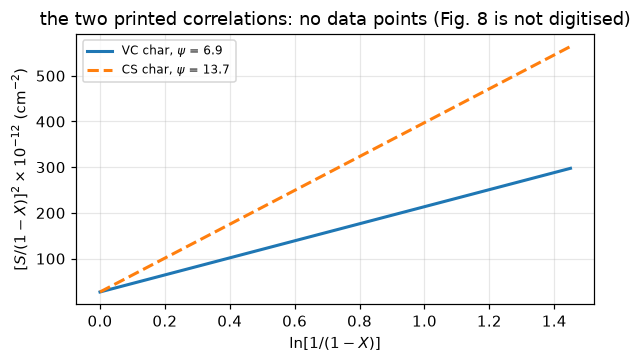


$S_o$ = 520 m²/cm³ for both chars is 5.20e+06 cm²/cm³, so the
shared intercept is 27.04 × 10¹² cm⁻² and the slopes are
186.6 and 370.4 × 10¹² cm⁻².
Both $\psi$ exceed 2, so eq. (33) predicts surface maxima at $X_M$ = 0.2989 (VC) and
0.3475 (CS); the paper says a maximum "was, in fact, reported in the reference
work for the CS char but did not show up for the VC char, obscured by the particle
attrition". The length-averaged pore radius is 0.5574$(1-\epsilon_o)$ nm (VC)
and 0.2807$(1-\epsilon_o)$ nm (CS): micropores at any porosity. These are
predictions of the model at the printed parameters, not a validation of it.
The effectiveness-factor sentence demands a sphere Thiele modulus below 0.5557;
whether the chars met it cannot be checked from this paper.


In [12]:
def char_numbers(So_m2=P["hashimoto_So"], to_cm2=1e4, swap=False):
    """Intercept, X_M and mean pore radius (nm per (1 - eps_o)) of the two chars."""
    So_ = So_m2 * to_cm2
    pVC, pCS = (P["hashimoto_psi_CS"], P["hashimoto_psi_VC"]) if swap else (P["hashimoto_psi_VC"], P["hashimoto_psi_CS"])
    return dict(intercept=So_**2 / 1e12, XM_VC=XM_eq33(pVC), XM_CS=XM_eq33(pCS),
                rbar_VC=2 / (pVC * So_) * 1e7, rbar_CS=2 / (pCS * So_) * 1e7)


CH = char_numbers()
claims.value("hashimoto_XM_VC", CH["XM_VC"], rtol=1e-6)
claims.value("hashimoto_XM_CS", CH["XM_CS"], rtol=1e-6)
claims.value("hashimoto_rbar_VC_nm", CH["rbar_VC"], rtol=1e-6)
claims.value("hashimoto_intercept_e12", CH["intercept"], rtol=1e-6)
PHI_098 = unique_root(lambda z: eta_sphere(z) - P["eta_min"], 1e-3, 10.0, n_scan=32)
claims.value("eta098_thiele_sphere", PHI_098, rtol=1e-6)
_sw, _nc = char_numbers(swap=True), char_numbers(to_cm2=1.0)
brk("the two chars' psi swapped (char_numbers(swap=True))", "hashimoto_XM_VC", _sw["XM_VC"])
brk("the two chars' psi swapped (char_numbers(swap=True))", "hashimoto_XM_CS", _sw["XM_CS"])
brk("the m2 -> cm2 conversion dropped (char_numbers(to_cm2=1))", "hashimoto_rbar_VC_nm", _nc["rbar_VC"])
brk("the m2 -> cm2 conversion dropped (char_numbers(to_cm2=1))", "hashimoto_intercept_e12", _nc["intercept"])
brk("eta read as 0.90 instead of 0.98", "eta098_thiele_sphere",
    unique_root(lambda z: eta_sphere(z) - 0.90, 1e-3, 10.0, n_scan=32))

xx = np.linspace(0, 1.45, 200)
fig, ax = plt.subplots(figsize=(5.6, 3.4))
for tag, psi_, st in (("VC", P["hashimoto_psi_VC"], "-"), ("CS", P["hashimoto_psi_CS"], "--")):
    ax.plot(xx, CH["intercept"] * (1 + psi_ * xx), st, lw=2, label=fr"{tag} char, $\psi$ = {psi_}")
ax.set(xlabel=r"$\ln[1/(1-X)]$", ylabel=r"$[S/(1-X)]^2 \times 10^{-12}$ (cm$^{-2}$)",
       title="the two printed correlations: no data points (Fig. 8 is not digitised)")
ax.legend(fontsize=8); fig.tight_layout(); plt.show()

display(Markdown(rf"""
$S_o$ = {P['hashimoto_So']:.0f} m²/cm³ for both chars is {P['hashimoto_So']*1e4:.2e} cm²/cm³, so the
shared intercept is {CH['intercept']:.2f} × 10¹² cm⁻² and the slopes are
{P['hashimoto_psi_VC']*CH['intercept']:.1f} and {P['hashimoto_psi_CS']*CH['intercept']:.1f} × 10¹² cm⁻².
Both $\psi$ exceed 2, so eq. (33) predicts surface maxima at $X_M$ = {CH['XM_VC']:.4f} (VC) and
{CH['XM_CS']:.4f} (CS); the paper says a maximum "was, in fact, reported in the reference
work for the CS char but did not show up for the VC char, obscured by the particle
attrition". The length-averaged pore radius is {CH['rbar_VC']:.4f}$(1-\epsilon_o)$ nm (VC)
and {CH['rbar_CS']:.4f}$(1-\epsilon_o)$ nm (CS): micropores at any porosity. These are
predictions of the model at the printed parameters, not a validation of it.
The effectiveness-factor sentence demands a sphere Thiele modulus below {PHI_098:.4f};
whether the chars met it cannot be checked from this paper.
"""))

## Validation

Nothing here is validated against data: there is none. What is validated is
that the page computes the paper's equations correctly, by routes that share
no code, and that every number it reports moves when a defect is injected.

### The rate law marched, against the closed form it never sees

Eq. (37) is the paper's *rate* law and eq. (32) its *integral*. Marching (37)
with Crank-Nicolson (a pymrm `newton` solve per step for all $\psi$ at once)
and comparing with (32) checks the printed pair against each other through
code that shares nothing with either. The step is refined and the observed
order taken from successive differences (`pymrm.checks.observed_orders`),
which needs no reference solution.

In [13]:
PSI_MARCH = np.array([0.0, 1.0, 2.0, 5.0, 10.0]); TAU_END = 1.5
NS = (100, 200, 400, 800)


def march_study(tau_end=TAU_END, theta=0.5, quarter=4.0):
    """Ladder of marches: observed orders, the finest error against eq. (32), finest difference over round-off."""
    vals = {}
    st = observed_orders(lambda n: vals.setdefault(n, march37(PSI_MARCH, tau_end, n, theta)), NS)
    err = float(np.max(np.abs(vals[NS[-1]] - X_of_tau(tau_end, PSI_MARCH, quarter=quarter))))
    findiff = float(np.max(np.abs(vals[NS[-1]] - vals[NS[-2]])))
    floor = NS[-1] * np.finfo(float).eps * float(np.max(np.abs(vals[NS[-1]])))
    return dict(orders=np.asarray(st["orders"], float), err=err, findiff=findiff, over_floor=findiff / floor,
                errs={n: float(np.max(np.abs(vals[n] - X_of_tau(tau_end, PSI_MARCH)))) for n in NS})


MS = march_study()
print(f"{'steps':>6}{'d_tau':>10}{'max |X_CN - eq. (32)|':>24}")
for n in NS:
    print(f"{n:6d}{TAU_END/n:10.6f}{MS['errs'][n]:24.4e}")
print(f"observed orders from successive differences: {np.array2string(MS['orders'], precision=4)}")
claims.value("march_cn_vs_eq32_max", MS["err"], rtol=0.05)
claims.bound("march_observed_order", float(MS["orders"][-1]), min=1.95, max=2.05, basis="theory",
             note="Crank-Nicolson is second order")
claims.bound("march_finest_over_roundoff", MS["over_floor"], min=1e3, basis="theory",
             note="finest successive difference over (steps x eps x max X), so the order is not fitted to noise")
ME = march_study(theta=1.0)
claims.value("march_euler_vs_eq32_max", ME["err"], rtol=0.05)
brk("implicit Euler instead of Crank-Nicolson (march37(..., theta=1))", "march_cn_vs_eq32_max", ME["err"])
brk("implicit Euler instead of Crank-Nicolson (march37(..., theta=1))", "march_observed_order", float(ME["orders"][-1]))
_q2 = float(np.max(np.abs(march37(PSI_MARCH, TAU_END, NS[-1]) - X_of_tau(TAU_END, PSI_MARCH, quarter=2.0))))
brk("eq. (32) with psi tau/2 for psi tau/4 (X_of_tau(..., quarter=2))", "march_cn_vs_eq32_max", _q2)
brk("eq. (32) with psi tau/2 for psi tau/4 (X_of_tau(..., quarter=2))", "march_euler_vs_eq32_max",
    float(np.max(np.abs(march37(PSI_MARCH, TAU_END, NS[-1], theta=1.0)
                        - X_of_tau(TAU_END, PSI_MARCH, quarter=2.0)))))
brk("ladder ended at tau = 1e-4, where the differences reach round-off (march37(..., tau_end=1e-4))",
    "march_finest_over_roundoff", march_study(tau_end=1e-4)["over_floor"])
print(f"Crank-Nicolson: {MS['err']:.2e} at {NS[-1]} steps; implicit Euler at the same steps "
      f"{ME['err']:.2e}, {ME['err']/MS['err']:.0f} times worse.")
print(f"finest successive difference over the round-off floor: {MS['over_floor']:.1e} (at least 1e3 required)")

 steps     d_tau   max |X_CN - eq. (32)|
   100  0.015000              6.2757e-06
   200  0.007500              1.5689e-06
   400  0.003750              3.9222e-07
   800  0.001875              9.8055e-08
observed orders from successive differences: [2. 2.]


Crank-Nicolson: 9.81e-08 at 800 steps; implicit Euler at the same steps 3.14e-04, 3198 times worse.
finest successive difference over the round-off floor: 1.7e+06 (at least 1e3 required)


### Everything else, two ways

Each quantity below is computed by two routes that share no code:
(a) $X_M$, eq. (33) against the root of the hand-written derivative of
eq. (31); (b) $\tau_{1/2}$, the pymrm block against a scalar root on eq. (32),
and at $\sigma = 10^9$ against the $\sigma\to\infty$ closed form
$\psi\tau^2/4 + \tau = \ln 2$; (c) Petersen's $S/S_o$ from eq. (3) against
the derivative of eq. (6); (d) Petersen's $X$ from eq. (6) against the
porosity route; (e) $I$ in closed form against Gauss-Legendre quadrature and
against a 40-digit quadrature (`mpmath`).

**(c) and (d) share algebra, and the page says which.** Substituting
$G = 3/(2u_o)$ and $\epsilon = 3u_o^2-2u_o^3$ into eq. (6) turns it into the
porosity route with $u = u_o(1+s)$, and its $s$-derivative into
$6u_o\,u(1-u)$. So (c) and (d) are round-off on an identity: what they can
detect is the root of eq. (7) and the transcription of eq. (4), not eq. (6)'s
own coefficients. And $X(s = 2G/3-1) = 1$ holds for **every** root of
eq. (7): with $(1+s) = 2G/3$ and $(G-1-s) = G/3$ the bracket of eq. (6) is
$(4G^3/27)/(G-1) - 1$, which eq. (7) turns into $1/\epsilon - 1$. That check
tests the joint transcription of (6) and (7), not the root; its break row
misreads eq. (7) itself.

In [14]:
PSI_XM = (3.0, 5.0, P["hashimoto_psi_VC"], P["hashimoto_psi_CS"])


def xm_two_routes(psi_scale=1.0, denom=2.0):
    """(a): eq. (33) against the root of dS/dX on (31)."""
    return max(abs(unique_root(lambda X: dSS0_dX(X, pv * psi_scale), 1e-12, 1 - 1e-12) - XM_eq33(pv, denom))
               / XM_eq33(pv, denom) for pv in PSI_XM)


claims.bound("XM_two_routes_rel", xm_two_routes(), max=1e-12, basis="tolerance",
             note="root tolerance 1e-15 on X_M")
brk("eq. (33) as (2-psi)/psi (XM_eq33(..., denom=1))", "XM_two_routes_rel", xm_two_routes(denom=1.0))
brk("psi 1 % adrift in the root route only", "XM_two_routes_rel", xm_two_routes(psi_scale=1.01))

PSI_B = np.array([0.0, 1.0, 2.0, 10.0, 100.0]); SIG_B = (0.25, 1.0, 10.0, 100.0)


def tau_half_scalar(pv, sg, how="root"):
    """tau_1/2 from eq. (32) by one scalar root, or read off a 200-point sweep (a defect)."""
    if how == "root":
        return unique_root(lambda z: X_of_tau(z, pv, sg) - 0.5, 1e-15, sg * (1 - 1e-13), n_scan=32, xtol=1e-17)
    g = np.linspace(1e-6, sg * (1 - 1e-9), 200)
    return g[np.argmin(np.abs(X_of_tau(g, pv, sg) - 0.5))]


TB = {(pv, sg): float(tau_at_X_block(0.5, [pv], sg)[0]) for pv in PSI_B for sg in SIG_B}
claims.bound("tau_block_vs_scipy_rel", max(abs(TB[k] - tau_half_scalar(*k)) / TB[k] for k in TB), max=1e-12,
             basis="tolerance", note="newton tol 1e-13 on w and root tolerance 1e-17 on tau")
brk("tau_1/2 read off a 200-point sweep (tau_half_scalar(..., how='sweep'))", "tau_block_vs_scipy_rel",
    max(abs(TB[k] - tau_half_scalar(*k, how="sweep")) / TB[k] for k in TB))


def tau_half_closed(pv, ln2=np.log(2)):
    """sigma -> infinity: psi tau^2/4 + tau = ln 2."""
    return ln2 if pv == 0 else (-1 + np.sqrt(1 + pv * ln2)) * 2 / pv


claims.bound("tau_closed_vs_block_rel",
             max(abs(tau_at_X_block(0.5, [pv], 1e9)[0] - tau_half_closed(pv)) / tau_half_closed(pv) for pv in PSI_B),
             max=1e-8, basis="theory", note="the block runs at sigma = 1e9; the gap is about 3 tau/sigma")
brk("the closed form with 2 ln 2 for ln 2 (tau_half_closed(..., ln2=2*log(2)))", "tau_closed_vs_block_rel",
    max(abs(tau_at_X_block(0.5, [pv], 1e9)[0] - tau_half_closed(pv, 2 * np.log(2))) / tau_half_closed(pv)
        for pv in PSI_B))

# the direct residual X(tau) - X* from the same start
_fail = 0
for pv in PSI_B:
    for sg in SIG_B:
        try:
            tau_at_X_block(0.5, [pv], sg, residual="direct")
        except NewtonBreakdown:   # newton raises it on an exactly singular Jacobian (status 5)
            _fail += 1
claims.exact("direct_residual_failures", _fail,
             note="newton on X(tau) - 1/2 from tau = sigma/2 over the 20 (psi, sigma) states")
_fail_log = sum(1 for pv in PSI_B for sg in SIG_B if not np.isfinite(TB[(pv, sg)]))
brk("the log residual in place of the direct one (tau_at_X_block(..., residual='log'))",
    "direct_residual_failures", _fail_log)
_flat = 1 - (1 - 0.5)**3 * np.exp(-50.0) - 0.5
print(f"direct residual: newton stops on {_fail} of the {len(TB)} (psi, sigma) states. From tau = sigma/2 at")
print(f"sigma = 100 the term (1 - tau/sigma)^3 exp(-tau(1 + psi tau/4)) is below the round-off of 1 even at")
print(f"psi = 0 (the residual is {_flat:.17g}, flat to the last bit) and underflows to 0 at psi = 100, so the")
print("differenced Jacobian is exactly singular; the log form has no exponential to lose.")

E_F4, E_F7 = P["fig4_eps_o"], P["fig7_eps_o"]
X_SS = (0.05, 0.25, 0.5, 0.75, 0.9, 0.99)
claims.bound("petersen_SS_two_routes",
             max(abs(SS0_pet_via_eq6(x, E_F4) - SS0_petersen(np.array([x]), E_F4)[0]) for x in X_SS),
             max=1e-14, basis="identity", note="eq. (6) differentiated is u(1 - u) once G = 3/(2 u_o)")
G_WRONG_F4 = float(cubic7_roots(E_F4)[1])
brk(f"the middle root of eq. (7) in the d(eq. 6)/ds route (SS0_pet_via_eq6(..., G={G_WRONG_F4:.4f}))",
    "petersen_SS_two_routes",
    max(abs(SS0_pet_via_eq6(x, E_F4, G_WRONG_F4) - SS0_petersen(np.array([x]), E_F4)[0]) for x in X_SS))
G_F7 = G_of_eps(E_F7)
sgrid = np.linspace(0, 2 * G_F7 / 3 - 1, 97)
claims.bound("petersen_X_two_routes", float(np.max(np.abs(X_petersen(sgrid, E_F7) - X_pet_via_eps(sgrid, E_F7)))),
             max=1e-14, basis="identity", note="eq. (6) is the porosity route once G = 3/(2 u_o)")
brk(f"the middle root of eq. (7) (X_petersen(..., G={G_WRONG:.4f}))", "petersen_X_two_routes",
    float(np.max(np.abs(X_petersen(sgrid, E_F7, G_WRONG) - X_pet_via_eps(sgrid, E_F7)))))


def endpoint_dev(coef=4 / 27):
    """|X(s = 2G/3 - 1) - 1| with G the largest root of eq. (7) read with ``coef``."""
    G = float(cubic7_roots(E_F7, coef)[-1])
    return float(abs(X_petersen(2 * G / 3 - 1, E_F7, G) - 1.0))


claims.bound("petersen_X_endpoint_dev", endpoint_dev(), max=1e-14, basis="identity",
             note="X = 1 at s = 2G/3 - 1 for every root of eq. (7)")
brk("eq. (7)'s 4/27 read as 2/27 (cubic7_roots(..., coef=2/27))", "petersen_X_endpoint_dev", endpoint_dev(2 / 27))
print(f"   the middle root leaves the endpoint at round-off: {float(abs(X_petersen(2*G_WRONG/3-1, E_F7, G_WRONG)-1)):.1e}"
      " (not a break row; it is the identity)")

# (e) the integral I
CASES_I = ((1.0, 2 / 3), (2.0, 0.49), (5.0, 0.4), (0.5, 0.8))
mpmath.mp.dps = 40


def I_40digit(pv, m_):
    """I by mpmath quadrature at 40 digits, as a float."""
    p_, m__ = mpmath.mpf(pv), mpmath.mpf(m_)
    f = lambda w: (w * mpmath.sqrt(1 - p_ * mpmath.log(w)) - w**m__)**2
    return mpmath.quad(f, [0, mpmath.mpf("1e-6"), mpmath.mpf("0.01"), mpmath.mpf("0.5"), 1])


I40 = {c: I_40digit(*c) for c in CASES_I}


def rel_to_40(fun):
    return max(float(abs(mpmath.mpf(fun(*c)) - I40[c]) / I40[c]) for c in CASES_I)


claims.bound("I_two_routes_rel", max(abs(I_gl(*c) - I_closed(*c)) / I_closed(*c) for c in CASES_I), max=1e-10,
             basis="tolerance", note="set by the cancellation in the closed form, see I_closed_vs_40digit_rel")
claims.bound("I_closed_vs_40digit_rel", rel_to_40(I_closed), max=1e-10, basis="tolerance",
             note="I is 1e-4 to 1e-1 of its terms, so the closed form loses that many digits to cancellation")
claims.bound("I_gl400_vs_40digit_rel", rel_to_40(I_gl), max=1e-13, basis="tolerance",
             note="400-point Gauss-Legendre on a smooth integrand, at round-off")
brk("the (1-X)^1 factor dropped in the quadrature (I_gl(..., p=0))", "I_two_routes_rel",
    max(abs(I_gl(*c, p=0) - I_closed(*c)) / I_closed(*c) for c in CASES_I))
brk("quadrature reduced to 25 nodes (I_gl(..., n=25))", "I_two_routes_rel",
    max(abs(I_gl(*c, n=25) - I_closed(*c)) / I_closed(*c) for c in CASES_I))
brk("the (1-X)^1 factor dropped in the closed form (I_closed(..., p=0))", "I_closed_vs_40digit_rel",
    rel_to_40(lambda pv, m_: I_closed(pv, m_, p=0)))
brk("quadrature reduced to 25 nodes (I_gl(..., n=25))", "I_gl400_vs_40digit_rel",
    rel_to_40(lambda pv, m_: I_gl(pv, m_, n=25)))

print(f"(a) X_M, eq. (33) against the root of dS/dX:                 below 1e-12 (here {claims['XM_two_routes_rel']:.1e})")
print(f"(b) tau_1/2, pymrm block against a scalar root, 20 states:  below 1e-12 (here {claims['tau_block_vs_scipy_rel']:.1e})")
print(f"    tau_1/2, block at sigma = 1e9 against the closed form:  below 1e-8 (here {claims['tau_closed_vs_block_rel']:.1e})")
print(f"(c) Petersen S/S_o, eq. (3) against d(eq. 6)/ds:            below 1e-14 (here {claims['petersen_SS_two_routes']:.1e})")
print(f"(d) Petersen X, eq. (6) against the porosity route:         below 1e-14 (here {claims['petersen_X_two_routes']:.1e})")
print(f"    eq. (6) at s = 2G/3 - 1 against X = 1:                  below 1e-14 (here {claims['petersen_X_endpoint_dev']:.1e})")
print(f"(e) I, closed form against Gauss-Legendre (400 points):     below 1e-10 (here {claims['I_two_routes_rel']:.1e})")
print(f"    closed form against 40 digits:                          below 1e-10 (here {claims['I_closed_vs_40digit_rel']:.1e})")
print(f"    Gauss-Legendre (400 points) against 40 digits:          below 1e-13 (here {claims['I_gl400_vs_40digit_rel']:.1e})")

direct residual: newton stops on 13 of the 20 (psi, sigma) states. From tau = sigma/2 at
sigma = 100 the term (1 - tau/sigma)^3 exp(-tau(1 + psi tau/4)) is below the round-off of 1 even at
psi = 0 (the residual is 0.5, flat to the last bit) and underflows to 0 at psi = 100, so the
differenced Jacobian is exactly singular; the log form has no exponential to lose.
   the middle root leaves the endpoint at round-off: 1.6e-15 (not a break row; it is the identity)


(a) X_M, eq. (33) against the root of dS/dX:                 below 1e-12 (here 1.3e-15)
(b) tau_1/2, pymrm block against a scalar root, 20 states:  below 1e-12 (here 5.8e-16)
    tau_1/2, block at sigma = 1e9 against the closed form:  below 1e-8 (here 3.0e-09)
(c) Petersen S/S_o, eq. (3) against d(eq. 6)/ds:            below 1e-14 (here 4.4e-16)
(d) Petersen X, eq. (6) against the porosity route:         below 1e-14 (here 1.7e-15)
    eq. (6) at s = 2G/3 - 1 against X = 1:                  below 1e-14 (here 2.2e-16)
(e) I, closed form against Gauss-Legendre (400 points):     below 1e-10 (here 7.6e-12)
    closed form against 40 digits:                          below 1e-10 (here 7.6e-12)
    Gauss-Legendre (400 points) against 40 digits:          below 1e-13 (here 8.5e-15)


### The quadrature axis, refined

$m^\star$ is a root of a quadrature-based derivative, so the node count is an
axis that would otherwise be invisible. Gauss-Legendre on this smooth
integrand converges exponentially, not at an algebraic order, and the table
shows where it stops: against the 40-digit $I$ it reaches round-off, while
against the closed form it stops at the closed form's own cancellation error.

In [15]:
print(f"{'nodes':>6}{'max rel err vs 40 digits':>27}{'vs closed form':>17}{'m*(1) - m*(1; 600 nodes)':>27}")
for n in (25, 50, 100, 200, 400):
    e40 = rel_to_40(lambda pv, m_: I_gl(pv, m_, n=n))
    ecl = max(abs(I_gl(*c, n=n) - I_closed(*c)) / I_closed(*c) for c in CASES_I)
    dm = m_star(1.0, n=max(n, 50)) - M1 if n >= 50 else np.nan
    print(f"{n:6d}{e40:27.3e}{ecl:17.3e}{dm:27.3e}")
claims.bound("mstar_node_sensitivity", abs(m_star(1.0, n=50) - M1), max=1e-8, basis="tolerance",
             note="m*(1) with 50 quadrature nodes in dI/dm against 600")
brk("quadrature reduced to 25 nodes in dI/dm (m_star(..., n=25))", "mstar_node_sensitivity",
    abs(m_star(1.0, n=25) - M1))

 nodes   max rel err vs 40 digits   vs closed form   m*(1) - m*(1; 600 nodes)
    25                  1.062e-03        1.062e-03                        nan
    50                  8.663e-08        8.663e-08                  1.394e-09
   100                  3.018e-14        7.571e-12                  2.477e-13
   200                  1.060e-14        7.604e-12                  2.568e-13
   400                  8.536e-15        7.605e-12                  1.713e-13


True

### The printed claims about particle size, measured

Two prose claims about Figure 2, each on the $\psi$ labels of Figure 2's
curves and each from the pymrm block inversion. At fixed $\tau$, eq. (32)'s
$X$ rises with $\psi$, so $\tau_{1/2}$ falls with $\psi$ and the spread across a
$\psi$ window sits on its endpoints.

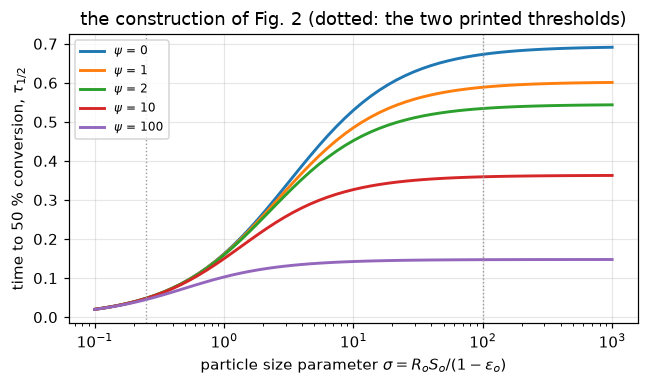


**Printed: "no further significant change occurs for $\sigma \ge 100$."** At $\sigma$ = 100,
$\tau_{1/2}$ differs from its $\sigma\to\infty$ value by at most
2.92 % over these $\psi$ (at $\psi$ = 0; only
0.36 % at $\psi$ = 100).
**Printed: "For small enough particles ($\sigma < 0.25$), the reaction time is
independent of internal structure for $\psi \le 100$."** At $\sigma$ = 0.25 it spreads
7.16 % across that window, against
57.7 % at $\sigma$ = 1: the printed threshold is doing
real work.


In [16]:
PSI_FIG2 = np.array([0.0, 1.0, 2.0, 10.0, P["sigma_small_psi_max"]])
sig_grid = np.geomspace(0.1, 1000.0, 61)
fig, ax = plt.subplots(figsize=(6.0, 3.6))
for pv in PSI_FIG2:
    ax.semilogx(sig_grid, tau_at_X_block(0.5, np.full(sig_grid.size, pv), sig_grid), lw=1.9, label=fr"$\psi$ = {pv:g}")
ax.axvline(P["sigma_plateau"], color="0.6", lw=0.9, ls=":")
ax.axvline(P["sigma_small"], color="0.6", lw=0.9, ls=":")
ax.set(xlabel=r"particle size parameter $\sigma = R_o S_o/(1-\epsilon_o)$", ylabel=r"time to 50 % conversion, $\tau_{1/2}$",
       title="the construction of Fig. 2 (dotted: the two printed thresholds)")
ax.legend(fontsize=8); fig.tight_layout(); plt.show()


def spread(sg):
    """Relative spread of tau_1/2 across the Fig. 2 psi labels at sigma = sg."""
    t = tau_at_X_block(0.5, PSI_FIG2, sg)
    assert np.all(np.diff(t) < 0)
    return float((t.max() - t.min()) / t.min())


t100 = tau_at_X_block(0.5, PSI_FIG2, P["sigma_plateau"])
tinf = np.array([tau_half_closed(pv) for pv in PSI_FIG2])
rel100 = np.abs(t100 - tinf) / tinf
claims.value("sigma100_max_rel", float(rel100.max()), rtol=1e-3)
claims.value("sigma025_psi_spread", spread(P["sigma_small"]), rtol=1e-3)
claims.value("sigma1_psi_spread", spread(1.0), rtol=1e-3)
brk("the (1 - tau/sigma)^3 factor dropped at sigma = 100 (tau_at_X_block(..., 1e12))", "sigma100_max_rel",
    float(np.max(np.abs(tau_at_X_block(0.5, PSI_FIG2, 1e12) - tinf) / tinf)))
brk("sigma read as 1 instead of 0.25", "sigma025_psi_spread", spread(1.0))
brk("sigma read as 0.25 instead of 1", "sigma1_psi_spread", spread(P["sigma_small"]))
display(Markdown(rf"""
**Printed: "no further significant change occurs for $\sigma \ge 100$."** At $\sigma$ = 100,
$\tau_{{1/2}}$ differs from its $\sigma\to\infty$ value by at most
{100*claims['sigma100_max_rel']:.2f} % over these $\psi$ (at $\psi$ = {PSI_FIG2[rel100.argmax()]:g}; only
{100*rel100[-1]:.2f} % at $\psi$ = 100).
**Printed: "For small enough particles ($\sigma < 0.25$), the reaction time is
independent of internal structure for $\psi \le 100$."** At $\sigma$ = 0.25 it spreads
{100*claims['sigma025_psi_spread']:.2f} % across that window, against
{100*claims['sigma1_psi_spread']:.1f} % at $\sigma$ = 1: the printed threshold is doing
real work.
"""))

### The reduction to the published `B3.1`

The abstract's first special case is the grain model, and its integrated form
at $m = 2/3$ is eq. (40), $X = 1-(1-\tau/3)^3$: the reaction-control shrinking
core, the published `B3.1`'s Yagi-Kunii eq. (6) in its $\omega\to0$ limit,
transcribed there from a 1955 Combustion Symposium scan.

**Reading `B3.1` before using it** (it has no `data/` directory, so what
travels is its findings):

- `B3.1` verifies its eq. (6) against an independent integration of eq. (5)'s
  three resistances, so the transcription used here is established there.
- `B3.1` states its reaction-control limit at $\omega = 10^{-9}$, not at
  $\omega = 0$. Its committed claim `eq6_to_reaction_limit` is loaded below
  and reproduced on `B3.1`'s own grid ($x = r/R$ at 400 points) before the
  exact limit is taken.
- **What this identity cannot see.** At $\omega = 0$ every $\omega$ term of
  eq. (6) drops out, so it is blind to all three $\omega$ coefficients; the
  numerator is $\gamma x$ and the denominator $\gamma$, so $\gamma$ cancels and
  its value is invisible too; and because $x = (1-X)^{1/3}$ and eq. (40)'s
  inversion are the same expression, a consistent slip in that exponent would
  cancel as well. What the identity sees is the ratio of the two $\gamma$
  coefficients and the exponent on $x$, and each has a break row.
- `B3.1`'s caveat that its absolute burnout times cannot be reconstructed
  does not touch this page: everything here is in $\tau$.

Bhatia eq. (40) against Yagi-Kunii eq. (6) at omega = 0, over gamma from 1e-6 to 1e12:
   max |diff| below 1e-15 (here 1.1e-16); the gamma range cannot fail, gamma cancels.
B3.1's committed eq6_to_reaction_limit = 3.848988e-10; recomputed here on B3.1's grid 3.848987e-10,
   relative difference below 1e-5 (here 2.9e-07): the 3.85e-10 is B3.1's omega = 1e-9, not a transcription difference.


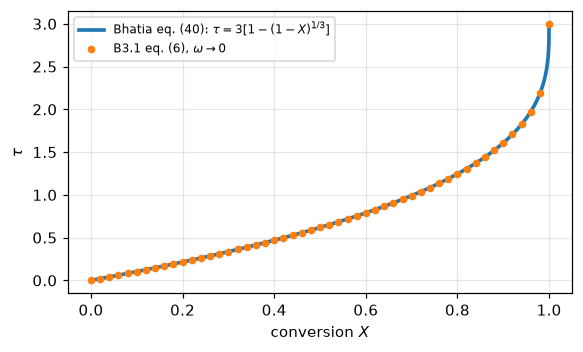

In [17]:
Xid = np.linspace(0, 1, 2001)
tau_over_3 = 1 - (1 - Xid)**(1 / 3)                      # eq. (40), inverted
GAMMAS = (1e-6, 1e-3, 1.0, 1e3, 1e12)


def b31_identity(**kw):
    """max |eq. (6) at omega = 0 - eq. (40)| over the gamma values (gamma cancels)."""
    return max(float(np.max(np.abs(yagi_kunii_eq6((1 - Xid)**(1 / 3), 0.0, g, **kw) - tau_over_3))) for g in GAMMAS)


x_b31 = np.linspace(0, 1, 400)                           # B3.1's grid of r/R


def b31_reaction_limit(**kw):
    """B3.1's eq6_to_reaction_limit, recomputed: max |eq. (6)(omega = 1e-9, gamma = 1) - (1 - x)|."""
    return float(np.max(np.abs(yagi_kunii_eq6(x_b31, 1e-9, 1.0, **kw) - (1 - x_b31))))


B31_COMMITTED = load_claims("B3.1-shrinking-core")["eq6_to_reaction_limit"]
claims.bound("b31_eq40_identity", b31_identity(), max=1e-15, basis="identity",
             note="eq. (6) at omega = 0 is 1 - x for every gamma")
claims.bound("b31_published_reconcile", abs(b31_reaction_limit() - B31_COMMITTED) / B31_COMMITTED, max=1e-5,
             basis="tolerance", note="round-off of a 4e-10 difference evaluated by two codes, eps/4e-10 = 6e-7")
brk("B3.1's eq. (6) numerator: gamma x read as gamma x^2 (yagi_kunii_eq6(..., x_power=2))", "b31_eq40_identity",
    b31_identity(x_power=2.0))
brk("B3.1's eq. (6): the numerator's gamma coefficient doubled (yagi_kunii_eq6(..., gamma_coef=2))",
    "b31_eq40_identity", b31_identity(gamma_coef=2.0))
brk("B3.1's eq. (6) numerator: gamma x read as gamma x^2 (yagi_kunii_eq6(..., x_power=2))",
    "b31_published_reconcile", abs(b31_reaction_limit(x_power=2.0) - B31_COMMITTED) / B31_COMMITTED)
print("Bhatia eq. (40) against Yagi-Kunii eq. (6) at omega = 0, over gamma from 1e-6 to 1e12:")
print(f"   max |diff| below 1e-15 (here {claims['b31_eq40_identity']:.1e}); the gamma range cannot fail, gamma cancels.")
print(f"B3.1's committed eq6_to_reaction_limit = {B31_COMMITTED:.6e}; recomputed here on B3.1's grid "
      f"{b31_reaction_limit():.6e},")
print(f"   relative difference below 1e-5 (here {claims['b31_published_reconcile']:.1e}): the 3.85e-10 is B3.1's "
      "omega = 1e-9, not a transcription difference.")

fig, ax = plt.subplots(figsize=(5.4, 3.3))
ax.plot(Xid, 3 * tau_over_3, lw=2.4, label=r"Bhatia eq. (40): $\tau = 3[1-(1-X)^{1/3}]$")
ax.plot(Xid[::40], 3 * yagi_kunii_eq6((1 - Xid[::40])**(1 / 3), 0.0, 1.0), "o", ms=4, label=r"B3.1 eq. (6), $\omega\to0$")
ax.set(xlabel="conversion $X$", ylabel=r"$\tau$"); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

### The reference table

`random-pore-reference.csv` holds the page's evaluation of eqs. (31)-(33),
$m^\star$ and $\tau_{1/2}$ on a grid of $(\psi, \tau)$, printed to 12
significant figures, so that an independent implementation can be tested
against it. These are model evaluations, not data. Every row is recomputed
here.

In [18]:
ref = load_data("random-pore-reference.csv", page=PAGE)


def ref_rows(quarter=4.0):
    """The reference table's columns, recomputed."""
    out = []
    for pv, tv in zip(ref.psi, ref.tau):
        Xv = float(X_of_tau(tv, pv, quarter=quarter))
        out.append([Xv, float(SS0_of_X(Xv, pv)), XM_eq33(pv) if pv >= 2 else np.nan, m_star(float(pv)),
                    tau_half_closed(pv)])
    return np.array(out)


def ref_dev(arr):
    tab = ref[["X", "S_over_So", "X_M", "m_star", "tau_half_sigma_inf"]].to_numpy(float)
    ok = np.isfinite(tab)
    assert np.array_equal(ok, np.isfinite(arr))
    return float(np.max(np.abs(arr[ok] - tab[ok]) / np.maximum(np.abs(tab[ok]), 1e-300)))


claims.bound("reference_csv_max_rel", ref_dev(ref_rows()), max=1e-11, basis="tolerance",
             note="the table is printed to 12 significant figures")
brk("eq. (32) with psi tau/2 for psi tau/4 (X_of_tau(..., quarter=2))", "reference_csv_max_rel",
    ref_dev(ref_rows(quarter=2.0)))
print(f"{len(ref)} rows of {ref.shape[1]} columns; largest relative deviation below 1e-11 "
      f"(here {claims['reference_csv_max_rel']:.1e})")

25 rows of 7 columns; largest relative deviation below 1e-11 (here 4.6e-12)


### The break table

Every number above is registered as a claim; each row injects one defect
through an argument or a parameter and reports what the claim becomes, and
whether the claim's own check catches it. Three candidate defects were tried
and cannot be rows, each for a measured reason printed under the table.

In [19]:
print(f"{'injected defect':<96} {'claim':<30} {'clean':>11} {'broken':>11}  caught")
for row, metric, clean, broken, caught in BREAK:
    if claims.metrics[metric]["kind"] == "bound":
        shown = f"(here {clean:.2g})"
    else:
        shown = f"{float(clean):11.5g}"
    print(f"{row[:96]:<96} {metric[:30]:<30} {shown:>11} {float(broken):11.5g}  {'yes' if caught else 'NO'}")
_caught = {m for _, m, _, _, c in BREAK if c}
_open = sorted(k for k in claims.metrics if k not in _caught and not claims.metrics[k].get("structural"))
print(f"\n{len(BREAK)} rows; {len(_caught)} of {len(claims.metrics)} claims are failed by at least one row; "
      f"structural: {', '.join(k for k in claims.metrics if claims.metrics[k].get('structural'))}; "
      f"open: {', '.join(_open) or 'none'}")
print("rows that do not fail their claim: "
      + ("; ".join(f"{r} -> {m}" for r, m, _, _, c in BREAK if not c) or "none"))

# candidate rows that cannot exist, each with its measured witness
_flip = lambda w_, pv: (lambda f: (f(w_ + 1e-9) - f(w_ - 1e-9)) / 2e-9)(lambda z: z * np.sqrt(1 + pv * np.log(z)))
FLIP_LO = np.exp(-1 / 5.0)
_inv35 = lambda e0: GHAT / (1 - e0) - 1 - np.log((1 - e0) / (1 - EPS_F))
_half20 = find_roots(lambda z: overlap_gap(z, avrami=0.5), 1e-6, 1.0, n_scan=64)["roots"]
print("\nCandidate rows that cannot exist:")
print(f" 1. eq. (31)'s radical sign flipped: (1-X) sqrt(1 + psi ln(1-X)) is real only for w > exp(-1/psi) = "
      f"{FLIP_LO:.4f} at psi = 5,\n    and increasing there (dS/dw = {_flip(FLIP_LO + 1e-6, 5.0):+.3e} and "
      f"{_flip(1 - 1e-9, 5.0):+.3e} at its ends): no maximum, so XM_two_routes_rel has nothing to compare.")
print(f" 2. eq. (35)'s log argument inverted: the residual is {_inv35(1e-12):+.4f} at eps_o -> 0 and "
      f"{_inv35(EPS_F - 1e-12):+.4f} at eps_o -> eps,\n    the same sign: no root in (0, eps).")
print(f" 3. eq. (20)'s exponent halved: Avrami's law then stays below Petersen's for every u > 0 "
      f"({len(_half20)} sign changes on (0, 1];\n    the gap is {float(overlap_gap(1.0, avrami=0.5)):+.4f} at u = 1), "
      "so overlap_cross_u has no crossing.")

injected defect                                                                                  claim                                clean      broken  caught
eq. (33) as (2-psi)/psi (XM_eq33(..., denom=1))                                                  XM_sup_vs_printed_rel            0.0011943     0.60845  yes
eq. (33) as (2-psi)/psi (XM_eq33(..., denom=1))                                                  XM_exceeds_printed_psi              1292.8      3.9938  yes
psi with (1 - eps_o) dropped (psi_of(..., keep_porosity=False))                                  psi_fig4_vs_printed_rel          0.0069348     0.34198  yes
psi with 2 pi for 4 pi (psi_of(..., coef=2*pi))                                                  psi_fig4_vs_printed_rel          0.0069348     0.50347  yes
eq. (3): the root above the surface maximum (petersen_audit(..., root='upper'))                  petersen_eps_rel_fig4set         0.0074286      1.8387  yes
eq. (3): the root above the surface maximum (petersen_a

## What pymrm adds

**Nothing to the model, and the page says so.** The random pore model is two
closed forms, and most of this notebook would run without pymrm. What pymrm
does here is narrow and real:

1. **Families of inversions as one Newton problem.** Eq. (32) inverted for
   $\tau$ across a block of $(\psi,\sigma)$, eq. (35) for $\epsilon_o$, and
   each implicit step of eq. (37) for all $\psi$, are one `newton` solve with
   `NumJac((K, 1))`: independent scalars, a diagonal Jacobian.
2. **A residual written so it can be solved.** The direct residual of eq. (32)
   from the start $\tau = \sigma/2$ stops `newton` on an exactly singular
   Jacobian (counted in the validation); the log form has no exponential to
   lose, and the sigmoid keeps $\tau$ inside $(0,\sigma)$.
3. **The rate law marched**, so that eqs. (37) and (32) check each other
   rather than being asserted equal, with the order from
   `pymrm.checks.observed_orders`.
4. **Every location is a root.** `pymrm.checks.find_roots` scans for every
   sign change before refining, so the two crossings of Figure 7's curves,
   the two roots of eq. (35) and the single minimiser of $I$ are counted,
   not assumed from a hand-chosen bracket.

The one output useful beyond reproduction is not pymrm at all: the
normalised misfit of the grain-shape-factor section, which turns "which grain
shape factor fits this pore structure" into a curve with an error attached,
and says what Figure 6 cannot: past $\psi = 2$ no order-of-reaction model
fits well, because none can produce a rate maximum.

## Reuse

**Use this page for** the random pore model itself: `X_of_tau` (eq. 32),
`SS0_of_X` (eq. 31), `XM_eq33` and `psi_of` are the whole kinetic-control
model, and `rate37` drops into any solid-conversion source term where the
surface evolves. `m_star(psi)` gives the grain shape factor equivalent to a
pore structure, and `I_nrms(psi, m)` says how badly that equivalence misfits:
check it before adopting an order-of-reaction model for a porous solid.
`u_of_eps`, `G_of_eps`, `X_petersen` and `SS0_petersen` are Petersen (1957)
as this paper reprints it, with the root of eq. (7) selected by construction.

**The traps:**

- **Eq. (7) has three real roots and the paper does not say which.** Only
  $G = 3/(2u_o)$, the largest, is consistent with eqs. (3), (4) and (6). The
  middle root puts complete gasification at a negative time and wrecks the
  Figure 7 comparison (the break table). It does **not** move the endpoint
  identity $X(s = 2G/3-1) = 1$, which holds for every root: that is not the
  check of a root selection.
- **$\psi$ carries $(1-\epsilon_o)$ and eq. (32) carries $\psi\tau/4$**, not
  $\psi\tau/2$; both have break rows.
- **Eq. (3) is not monotone in $r_p$.** It has two roots for any attainable
  $S$ (the physical one below $r_p\sqrt{\pi L/3} = 1/2$) and none above
  $S_{\max}(L)$, which is Figure 7's curve C.
- **Eq. (32) cannot be inverted naively**: from a start deep in the
  conversion the exponential vanishes against 1. Use the log residual.
- **$I$ in closed form loses digits to cancellation** when the misfit is
  small; for a small misfit integrate it directly.

**Do not use this page as evidence about any real solid.** Its only
experimental content is a figure it deliberately does not touch. The three
char numbers are transcribed prose, and everything derived from them is a
prediction of the model at those parameters. Anyone with the Hashimoto et al.
(1979) tables can build the comparison this page leaves open. **Do not
extrapolate past kinetic control**: Part II (not on disk) lifts it, and
`B3.2` is the neighbouring page where intergrain diffusion matters.

**Related pages.** `B3.1` (shrinking core), `B3.2` (grain model), `B3.4`,
`B1.1` (porous catalyst pellet).

**Cite the source, not this page:** Bhatia, S. K. and Perlmutter, D. D.
(1980). A random pore model for fluid-solid reactions: I. Isothermal, kinetic
control. *AIChE Journal* **26**(3), 379-386,
[doi:10.1002/aic.690260308](https://doi.org/10.1002/aic.690260308).
Petersen (1957), Szekely, Evans and Sohn (1976), Avrami (1940) and
Hashimoto et al. (1979) are cited by the paper and were not consulted; every
statement about "Petersen's model" here is about the paper's reprint of it.

In [20]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for B3.3:
  sym_zero_identity_count       = 15               exact  exact
  XM_sup_vs_printed_rel         = 0.0011943        value  rtol 0.001
  XM_exceeds_printed_psi        = 1292.8           value  rtol 0.0001
  psi_fig4_vs_printed_rel       = 0.0069348        value  rtol 0.001
  petersen_eps_rel_fig4set      = 0.0074286        value  rtol 0.001
  petersen_S_rel_fig4set        = 0.0021457        value  rtol 0.001
  petersen_eps_rel_fig7AB       = 0.025173         value  rtol 0.001
  curveC_So_over_Smax           = 4.5956           value  rtol 0.0001
  curveD_L_over_LAB             = 24.672           value  rtol 0.0001
  curveD_roundtrip_rel          = (here 1.1e-15)   bound  bound <= 1e-14 [identity]
  fig7_max_dX_upto_75           = 0.021759         value  rtol 0.001
  fig7_X_at_two_points          = 0.74232          value  rtol 0.0001
  fig7_early_cross_X            = 0.02318          value  rtol 0.001
  fig7_second_cross_X           = 0.62574          value  rtol 0.001
  f